# Supplementary Material — Part II: results and method defence (S8–S21)

Companion to `paper_main_figures.ipynb`. This notebook re-runs the **same** extremes pipeline as the
main text and carries (a) the detail the main figures leave out and (b) the checks that decide whether
the method holds up.

| # | Figure | What it answers |
|---|---|---|
| **S8** | CORDEX vs CERRA in energy space | *The threshold is calibrated on CERRA and applied to CORDEX — are the two even on the same scale?* |
| **S9** | Threshold calibration + coverage | How the p95 deficit level is set |
| **S10** | Residual-load distributions, all zones × all seasons | The full picture behind Fig 2 |
| **S11** | Tail survival, MAM & SON | Fig 2's machinery for the two seasons it omits |
| **S12** | Zone × season % change in event count | The heatmap moved out of Figs 3–4 |
| **S13** | Wilcoxon signed-rank + ensemble agreement | *Which changes are actually significant at n = 9?* |
| **S14** | Per-driver attribution spread | The error bars Figs 3c/4c deliberately omit |
| **S15** | Diurnal event profiles | *Are sub-daily events really the evening PV cliff?* |
| **S16** | Level vs persistence | The multi-day decline is fewer events, not shorter ones |
| **S17** | Zone-pair co-occurrence | Compound / systemic risk |
| **S18** | Unserved energy | The operator-relevant metric |
| **S19** | Threshold convention (annual vs seasonal p95) | Why one absolute level, not a per-season one |
| **S20** | Scenario sensitivity — LOW/2050 vs HIGH/2040 | *Is the southern surge an artifact of the LOW build-out?* |
| **S21** | Flexibility counterfactual — with vs without batteries | How much do batteries actually absorb? |

**S8, S20 and S21 are the figures that decide acceptance.** They are reported as they come out,
including where they are unflattering.

*Ensemble of 9 chains throughout; boxes/shading = inter-model spread; hatching or × = fewer than 2/3
(6/9) chains agree on the sign.*


## 0 · Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy_analysis.extremes_analysis import (
    attribution_change_by_model,
    compute_annual_operation_curves,
    compute_deficit_budget,
    compute_duration_stratified_metrics,
    compute_evening_peak_attribution,
    compute_event_significance,
    compute_multi_day_table,
    compute_seasonal_duration_stratified_metrics,
    compute_threshold_sensitivity,
    compute_unserved_energy_fraction,
    compute_zone_pair_cooccurrence_by_duration,
    compute_zone_season_change,
    extract_event_diurnal_profiles,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.extremes_events import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
)
from cordex2energy_analysis.extremes_thresholds import (
    calibrate_seasonal_active_thresholds,
    compute_active_threshold,
    diagnose_threshold_coverage,
)
from cordex2energy_analysis.plotting_extremes import (
    plot_event_diurnal_profile,
    plot_residual_load_kde,
)
from cordex2energy_analysis.plotting_paper import (
    PaperStyle,
    plot_cooccurrence,
    plot_level_vs_persistence,
    plot_significance,
    plot_tail_survival,
    plot_threshold_calibration,
    plot_threshold_sensitivity,
    plot_zone_season_change,
)
from cordex2energy_analysis.plotting_si import (
    plot_cerra_vs_cordex,
    plot_driver_attribution_spread,
    plot_flexibility_counterfactual,
    plot_scenario_sensitivity,
    plot_seasonal_operation,
)
from cordex2energy.utils.constants import REFERENCE_PERIOD

sns.set_style("whitegrid", {"grid.color": ".93"})
plt.rcParams["hatch.linewidth"] = 0.6

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [ ]:
# ── Configuration — mirrors paper_main_figures.ipynb exactly; the two must not drift apart ──
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_RESIDUAL_LOAD = PATH_PROCESSED / "extremes" / "residual_load"
FIGS = Path(paths.get("path_figs", "../figs")) / "paper_si"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
# The run the paper is built on, plus the HIGH/2040 build-out used by S20.
# (S21's no-battery counterfactual is reconstructed from THIS run — see remove_batteries.)
RUN_TAG = "DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
RUN_TAG_HIGH_2040 = "DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"   # S20

THRESHOLD_PERCENTILE = 95.0
EVENT_DETECTION = "spa"
WARMING_LEVELS = [1.5, 2.0, 3.0]
DURATION_BINS = {"sub_daily": (0, 24), "multi_day": (24, float("inf"))}
ROBUSTNESS_FRACTION = 2 / 3
SPREAD = "minmax"
COOCCURRENCE_WINDOW_STEPS = 8            # 8 × 3 h = ±24 h

SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {s: [m for m, name in SEASON_MAP.items() if name == s] for s in SEASON_ORDER}

DRIVER_PALETTE = {"Demand": "#D95F02", "PV": "#E6AB02", "Wind Onshore": "#7570B3",
                  "Wind Offshore": "#1B7C3D", "Hydro RoR": "#3182BD",
                  "Reservoir Hydro": "#08519C", "Battery": "#8B5A2B"}
DURATION_PALETTE = {"sub_daily": "#3182bd", "multi_day": "#e6550d"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]

ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberian Peninsula", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}

### The pipeline, as a function of the run tag

S20 and S21 need the *same* analysis on a *different* run, so the load-and-prepare step is written once
and called three times. Anything that differs between the three runs is a genuine scenario difference,
never a difference in how the analysis was done.

In [4]:
def load_run(run_tag: str, *, threshold_from: str = "cerra"):
    """Load one residual-load run and prepare everything the event statistics need.

    ``threshold_from``:
      * ``"cerra"``   — calibrate the p95 deficit level on that run's own CERRA reanalysis pass.
        Correct when the *system* changes (S20: a different build-out is a different system, so its
        reference deficit distribution is different too).
      * an ``xr.DataArray`` — reuse a threshold calibrated elsewhere. Correct when the question is
        "what does this component absorb?" (S21: re-calibrating without batteries would move the
        goalposts by exactly the effect being measured).
    """
    zonal_rl, zonal_components = [], []
    for folder in sorted(PATH_RESIDUAL_LOAD.glob("*")):
        run_dir = folder / run_tag
        if not folder.is_dir() or folder.name == "cerra" or not run_dir.exists():
            continue
        model = "_".join(folder.name.split("_")[:-1])
        zonal_rl.append(xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(model=[model]))
        zonal_components.append(
            xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(model=[model]))
    zonal_rl = xr.concat(zonal_rl, dim="model", join="outer")
    zonal_components = xr.concat(zonal_components, dim="model", join="outer")

    run_models = list(zonal_rl["model"].values)
    run_zones = [z for z in ZONE_ORDER if z in [str(x) for x in zonal_rl["zone"].values]]

    # The threshold.
    cerra_deficit = None
    if isinstance(threshold_from, str) and threshold_from == "cerra":
        cerra_dir = PATH_RESIDUAL_LOAD / "cerra" / run_tag
        cerra_rl = xr.open_dataset(cerra_dir / "residual_load_zonal.nc")
        cerra_components = xr.open_dataset(cerra_dir / "components_zonal.nc")
        shared = np.intersect1d(cerra_rl.time.values, cerra_components.time.values)
        cerra_rl, cerra_components = cerra_rl.sel(time=shared), cerra_components.sel(time=shared)
        cerra_metrics = compute_continuous_system_metrics(
            cerra_rl, cerra_components, calculate_climatological_baseline(cerra_components))
        cerra_deficit = cerra_metrics["residual_load"].where(cerra_metrics["residual_load"] > 0)
        threshold = compute_active_threshold(cerra_deficit, "PERCENTILE",
                                             percentile=THRESHOLD_PERCENTILE)
    else:
        threshold = threshold_from

    by_model, components_by_model, metrics_by_model = {}, {}, {}
    for model in run_models:
        rl = zonal_rl.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
        comp = (zonal_components.sel(model=model).drop_vars("model", errors="ignore")
                .dropna("time", how="all"))
        shared = np.intersect1d(rl.time.values, comp.time.values)
        by_model[model] = rl.sel(time=shared)
        components_by_model[model] = comp.sel(time=shared)
        metrics_by_model[model] = compute_continuous_system_metrics(
            by_model[model], components_by_model[model],
            calculate_climatological_baseline(
                components_by_model[model].sel(time=slice(*REFERENCE_PERIOD))))

    return dict(
        run_tag=run_tag, models=run_models, zones=run_zones,
        residual_load=by_model, components=components_by_model, metrics=metrics_by_model,
        threshold=threshold, threshold_by_model={m: threshold for m in run_models},
        cerra_deficit=cerra_deficit, zonal_rl=zonal_rl,
    )


def event_tables(run: dict, period_defs: dict):
    """The two event tables — both scored against the run's single absolute threshold."""
    per_season = {str(z): {s: float(run["threshold"].sel(zone=z)) for s in SEASON_ORDER}
                  for z in run["zones"]}
    annual = compute_duration_stratified_metrics(
        run["residual_load"], run["metrics"], run["threshold_by_model"], period_defs,
        run["models"], run["zones"], method=EVENT_DETECTION, duration_bins=DURATION_BINS)
    seasonal = compute_seasonal_duration_stratified_metrics(
        run["residual_load"], run["metrics"], {m: per_season for m in run["models"]}, period_defs,
        run["models"], run["zones"], SEASON_ORDER, SEASON_MONTHS,
        method=EVENT_DETECTION, duration_bins=DURATION_BINS)
    return annual, seasonal, per_season



def remove_batteries(run: dict) -> dict:
    """The battery-free counterfactual, reconstructed from the SAME sysflex run — no second simulation.

    In the sysflex scheme the reservoir is dispatched FIRST and independently, then the battery operates
    on the reservoir-adjusted load (verified in compute_tyndp_projections_extremes.py). The saved
    ``battery_dispatch_gwh = RL_before_battery - RL_after_battery`` (positive = discharge), so adding it
    back recovers the pre-battery residual load with the reservoir dispatch held EXACTLY fixed:

        RL_no_battery = residual_load + battery_dispatch_gwh

    This isolates the battery cleanly. Loading the standalone no-battery tag instead would also change
    the reservoir dispatch (checked: Central-East reservoir 8 vs 39 TWh/yr, Nordic 175 vs 1) and
    confound the comparison, so it is deliberately not used.
    """
    residual_load, metrics = {}, {}
    for model in run["models"]:
        rl = run["residual_load"][model].copy()
        rl["residual_load"] = rl["residual_load"] + run["components"][model]["battery_dispatch_gwh"]
        residual_load[model] = rl
        metrics[model] = compute_continuous_system_metrics(
            rl, run["components"][model],
            calculate_climatological_baseline(
                run["components"][model].sel(time=slice(*REFERENCE_PERIOD))))
    return {**run, "residual_load": residual_load, "metrics": metrics}


In [5]:
started = time.perf_counter()
main = load_run(RUN_TAG)
models, zones = main["models"], main["zones"]

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS,
    models=models,
    chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO,
)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

STYLE = PaperStyle(
    zones=zones, zone_labels=ZONE_LABELS, period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)),
    driver_palette=DRIVER_PALETTE, duration_palette=DURATION_PALETTE,
    season_order=SEASON_ORDER, n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD, spread=SPREAD,
)

events_annual, events_by_season, zone_threshold_by_season = event_tables(main, period_defs)
zone_threshold = main["threshold"]

print(f"{len(models)} chains × {len(zones)} zones  [{time.perf_counter() - started:.0f}s]")
print(f"events_annual {events_annual.shape} | events_by_season {events_by_season.shape}")

9 chains × 6 zones  [22s]
events_annual (324, 26) | events_by_season (1296, 27)


In [6]:
# ── The derived tables the figures below are drawn from ────────────────────────────────
# Identical calls to paper_main_figures.ipynb, so S11/S14/S16 plot exactly the quantities the main
# figures do. If these drift, the SI stops defending the paper and starts contradicting it.
deficit_budget, diurnal_profiles = compute_deficit_budget(
    main["residual_load"], main["threshold_by_model"], period_defs, zones, method=EVENT_DETECTION)

# Fig 3c is drawn from this one (evening peak, 15–21 UTC).
evening_peak_components = compute_evening_peak_attribution(
    main["residual_load"], main["components"], period_defs, zones, SEASON_MAP)

# Fig 4c from this one. Within-season attribution is mandatory: warming moves these events from
# winter to summer in the Mediterranean, so pooling seasons would confound that recomposition of the
# event population with the physical change.
multi_day_events, multi_day_by_season = compute_multi_day_table(
    main["residual_load"], main["components"], main["threshold_by_model"], period_defs, zones,
    SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION)

print(f"deficit_budget {deficit_budget.shape} | evening_peak {evening_peak_components.shape} "
      f"| multi_day {multi_day_events.shape}")

deficit_budget (162, 7) | evening_peak (486, 12) | multi_day (162, 21)


## S8 · Does CORDEX reproduce CERRA in energy space?

**The paper's most attackable assumption.** The deficit threshold is the 95th percentile of the
positive residual load in the **CERRA** reanalysis, and it is then applied to **CORDEX**. If the two
disagree about the reference-period residual load, every event count in the paper inherits that bias.

So: per zone, the reference-period residual-load distribution of the 9 chains against CERRA's, and the
p95 threshold each of them implies. The bias is printed, not buried.

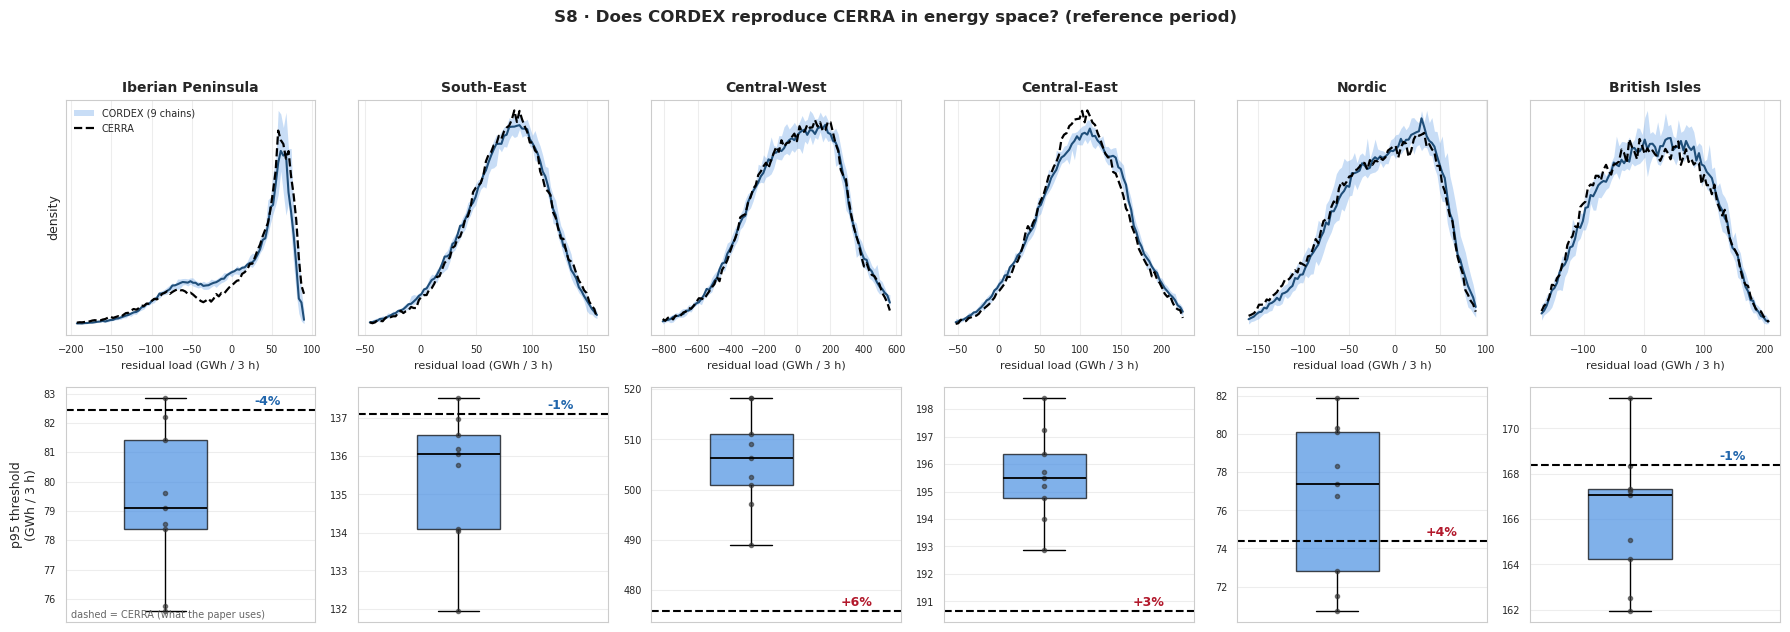

Threshold bias, CORDEX (9-chain median) vs CERRA — the number the paper must state:
             zone      cerra  cordex_median  bias_pct
Iberian_Peninsula  82.440097      79.090274 -4.063341
       South_East 137.100462     136.045087 -0.769783
  Central_Western 475.760944     506.198979  6.397758
  Central_Eastern 190.640379     195.507375  2.552972
           Nordic  74.367451      77.374311  4.043248
    British_Isles 168.371185     167.067756 -0.774140


In [7]:
# The CORDEX reference-period residual load, per chain, and the threshold each chain would imply.
cordex_reference, cordex_threshold = {}, {}
for model in models:
    window = period_defs[REFERENCE][model]
    reference_slice = main["metrics"][model].sel(time=slice(str(window[0]), str(window[1])))
    cordex_reference[model] = reference_slice
    deficit = reference_slice["residual_load"].where(reference_slice["residual_load"] > 0)
    cordex_threshold[model] = compute_active_threshold(deficit, "PERCENTILE",
                                                       percentile=THRESHOLD_PERCENTILE)

cerra_reference = compute_continuous_system_metrics(
    *[xr.open_dataset(PATH_RESIDUAL_LOAD / "cerra" / RUN_TAG / f)
      for f in ("residual_load_zonal.nc", "components_zonal.nc")],
    calculate_climatological_baseline(
        xr.open_dataset(PATH_RESIDUAL_LOAD / "cerra" / RUN_TAG / "components_zonal.nc")))

fig = plot_cerra_vs_cordex(cordex_reference, cerra_reference, cordex_threshold, zone_threshold, STYLE)
fig.savefig(FIGS / "S8_cerra_vs_cordex.png", dpi=200, bbox_inches="tight")
plt.show()

print("Threshold bias, CORDEX (9-chain median) vs CERRA — the number the paper must state:")
print(fig.bias_table.to_string(index=False))

## S9 · Threshold calibration (CERRA p95) and coverage diagnostic

How the single absolute deficit level per zone is set, and what fraction of the reference climate it
actually selects.

Annual coverage (CERRA):
             zone season  positive_fraction  threshold_gwh  threshold_floored_gwh  degenerate
    British_Isles    ALL                1.0     168.371185             168.371185       False
  Central_Eastern    ALL                1.0     190.640379             190.640379       False
  Central_Western    ALL                1.0     475.760944             475.760944       False
Iberian_Peninsula    ALL                1.0      82.440097              82.440097       False
           Nordic    ALL                1.0      74.367451              74.367451       False
       South_East    ALL                1.0     137.100462             137.100462       False


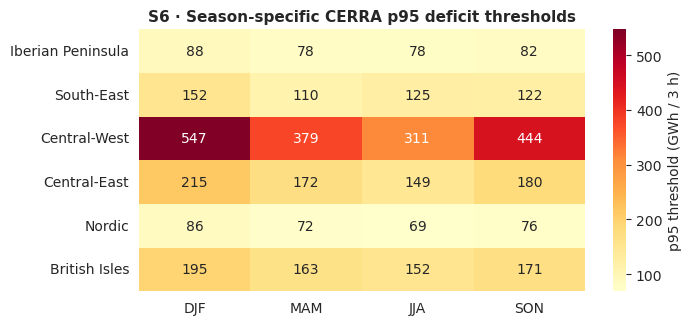

In [8]:
coverage = diagnose_threshold_coverage(main["cerra_deficit"], thresholds=zone_threshold)
print("Annual coverage (CERRA):")
print(coverage.to_string(index=False))

seasonal_thresholds, _ = calibrate_seasonal_active_thresholds(
    main["cerra_deficit"], zones, SEASON_ORDER, SEASON_MONTHS, "PERCENTILE",
    percentile=THRESHOLD_PERCENTILE)          # the rejected alternative — used by S9 and S19

fig = plot_threshold_calibration(seasonal_thresholds, STYLE)
fig.savefig(FIGS / "S9_threshold_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

## S10 · Residual-load distributions — every zone, every season

The full picture behind Fig 2, which shows only DJF and JJA. The bulk of the distribution shifts
toward surplus almost everywhere — which is precisely why the paper argues from the **tail** (S11) and
not from the mean.

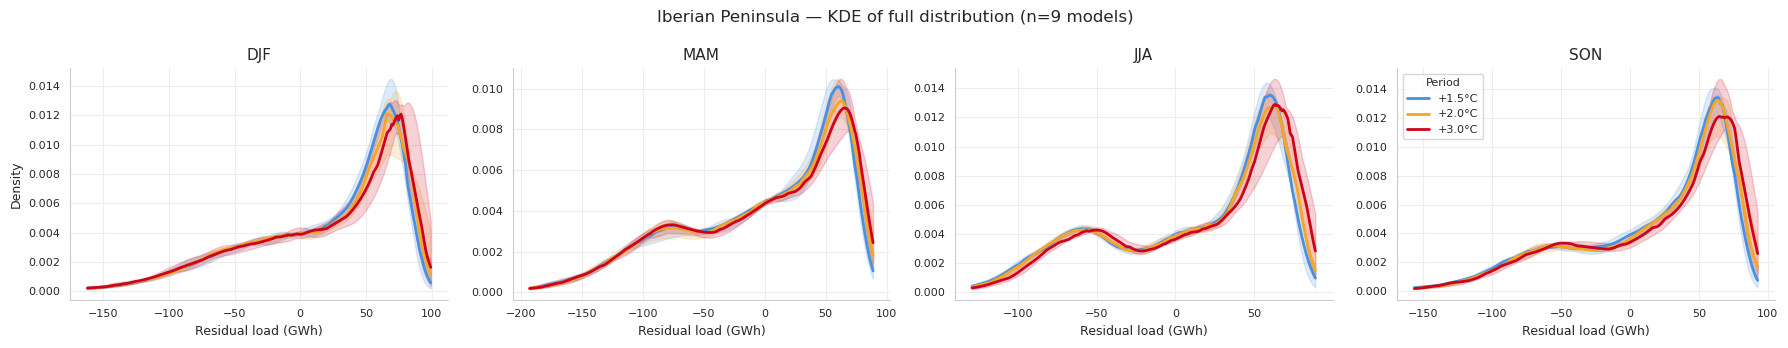

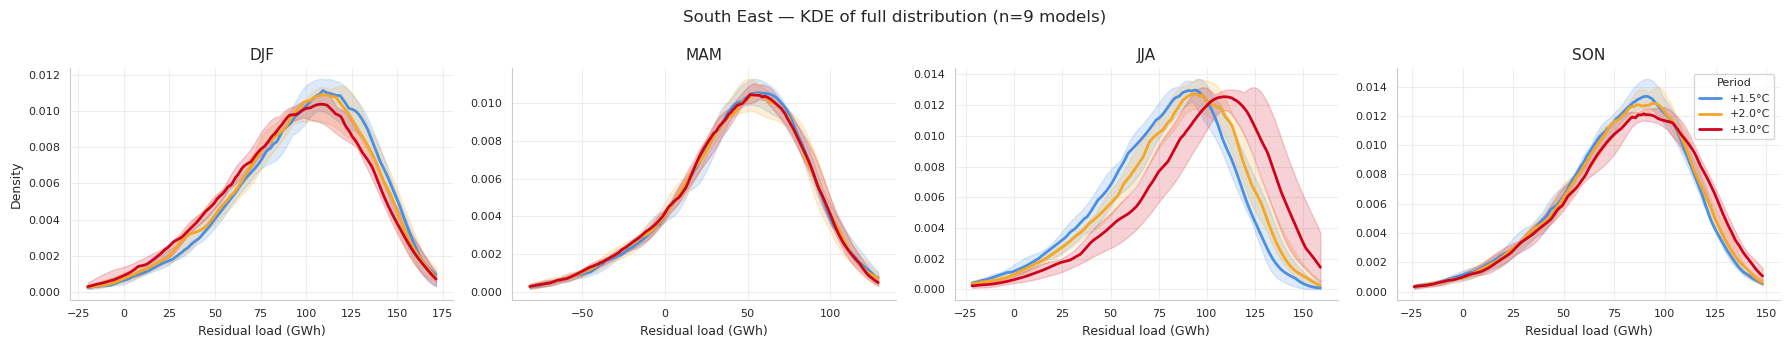

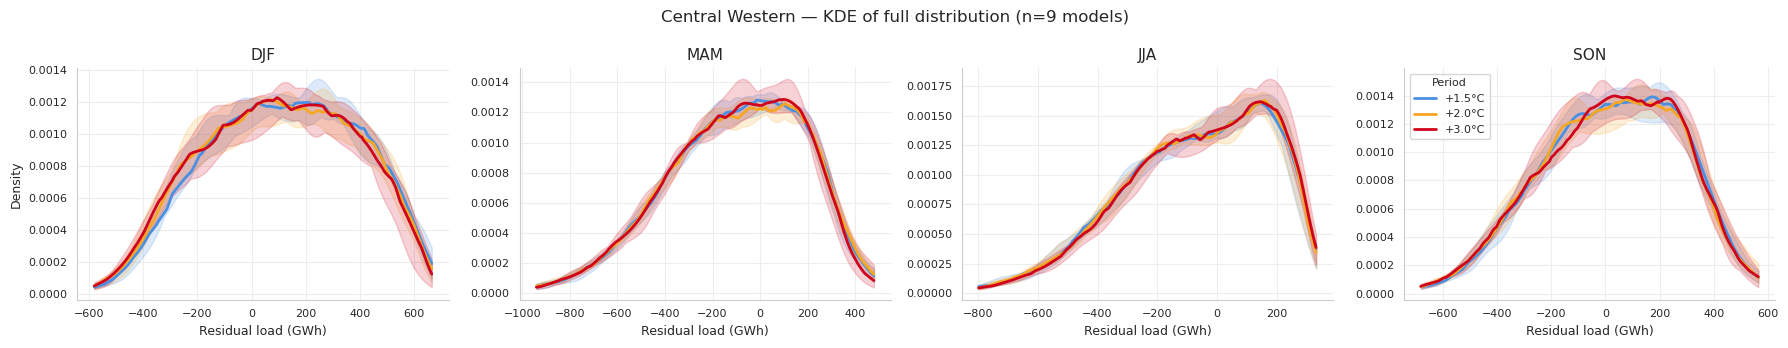

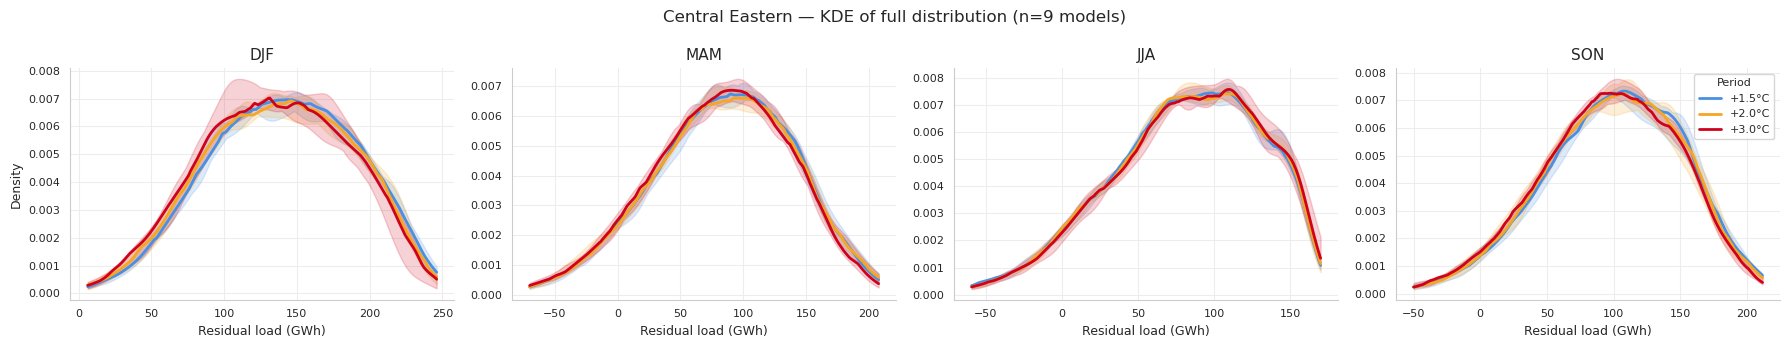

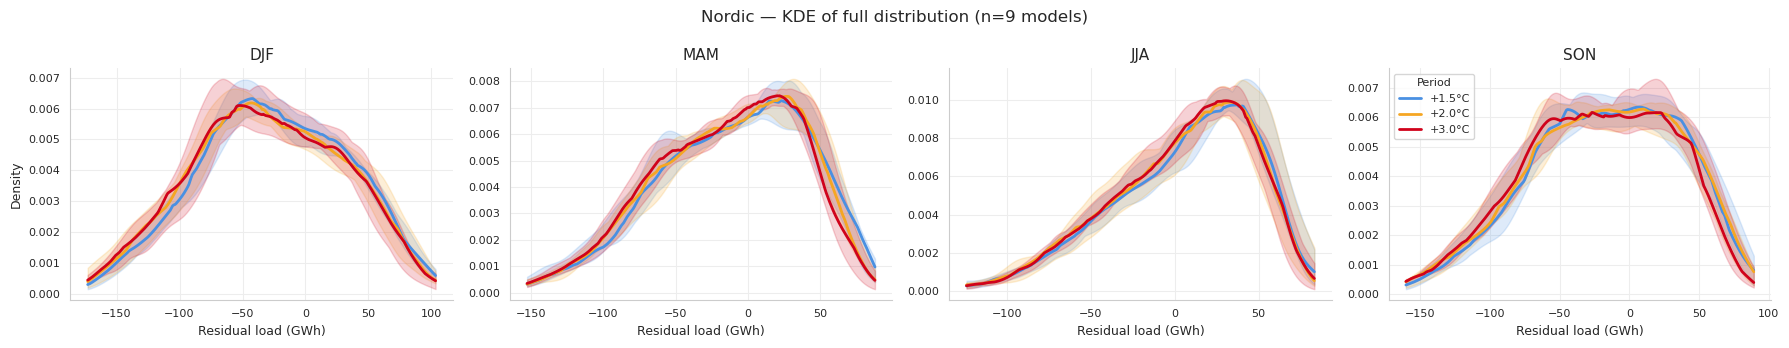

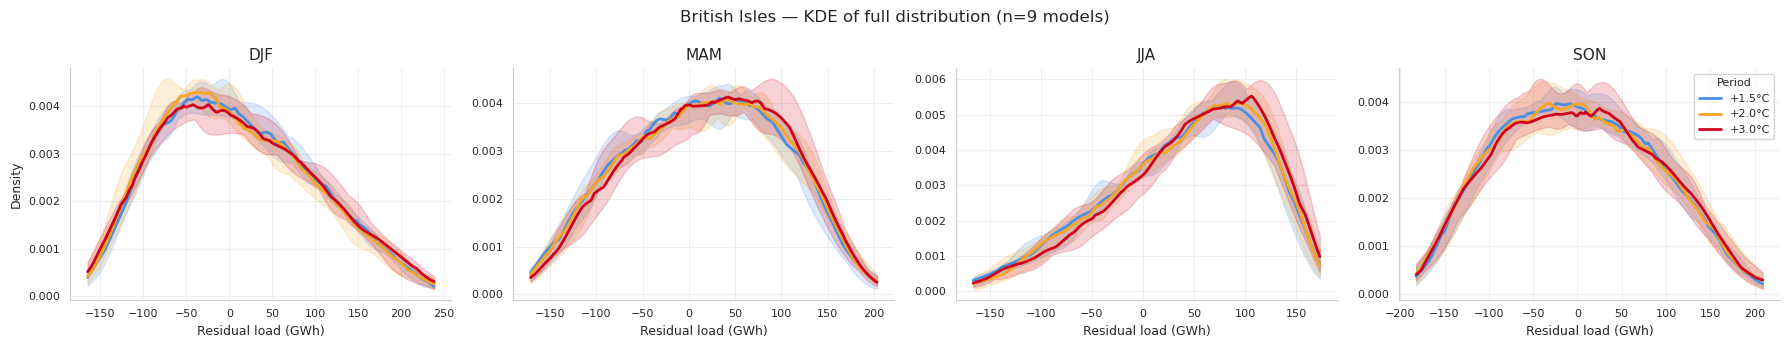

In [9]:
plot_residual_load_kde(
    main["zonal_rl"], zones, period_defs,
    period_colors=dict(zip(period_names, GWL_COLORS)),
    models=models, season_map=SEASON_MAP, season_order=SEASON_ORDER,
    threshold=None, spread=SPREAD,
    path_savefig=FIGS / "S10_residual_load_kde.png")

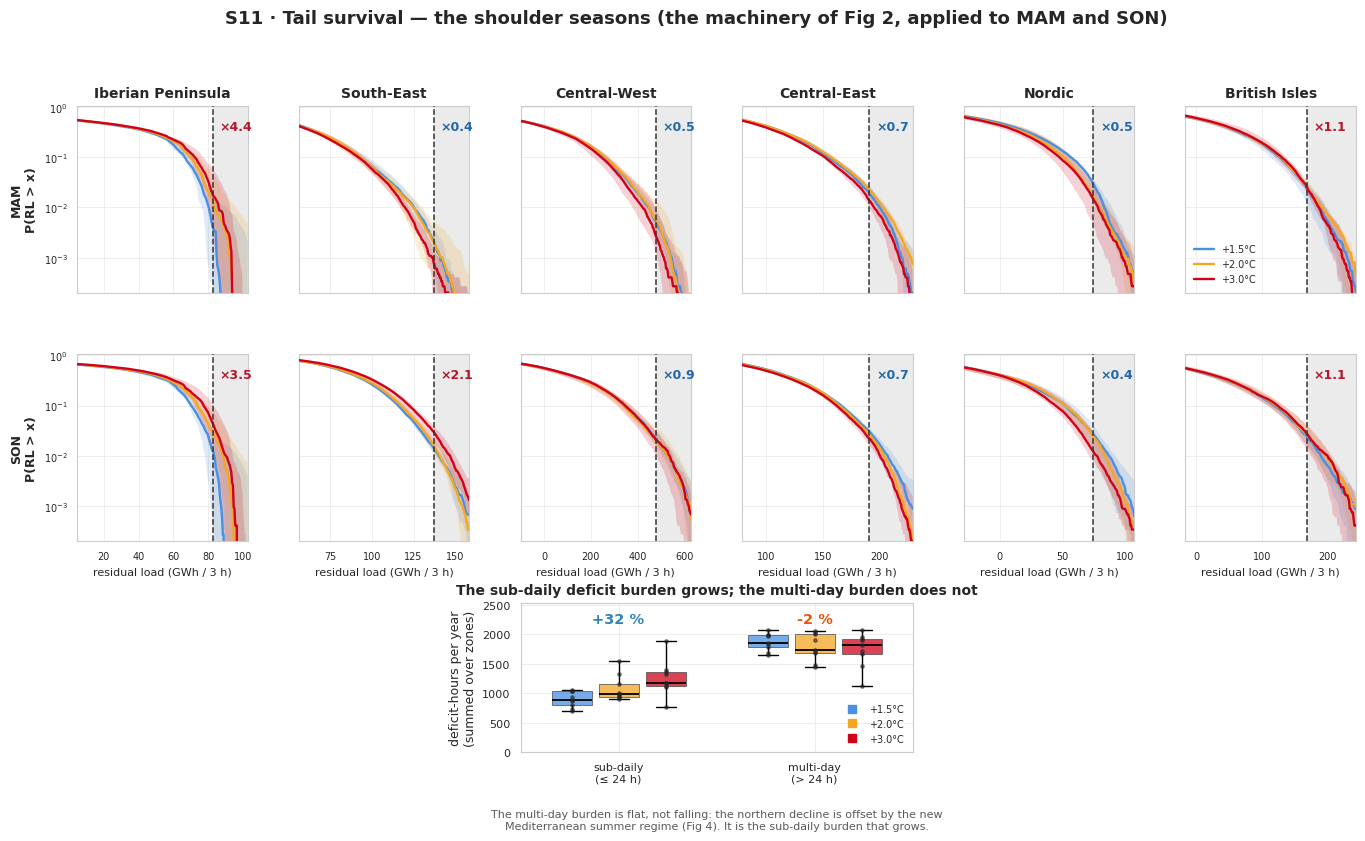

In [10]:
fig = plot_tail_survival(
    main["residual_load"], period_defs, zone_threshold, deficit_budget, STYLE, SEASON_MONTHS,
    seasons=("MAM", "SON"),
    title="S11 · Tail survival — the shoulder seasons (the machinery of Fig 2, applied to MAM and SON)")
fig.savefig(FIGS / "S11_tail_survival_shoulder.png", dpi=200, bbox_inches="tight")
plt.show()

## S12 · Zone × season % change in event count (both duration classes)

Moved out of the main text to keep Figs 3–4 to four panels. Cells show the ensemble-median % change
with the inter-model spread; **×** marks fewer than 2/3 (6/9) chains agreeing on the sign.

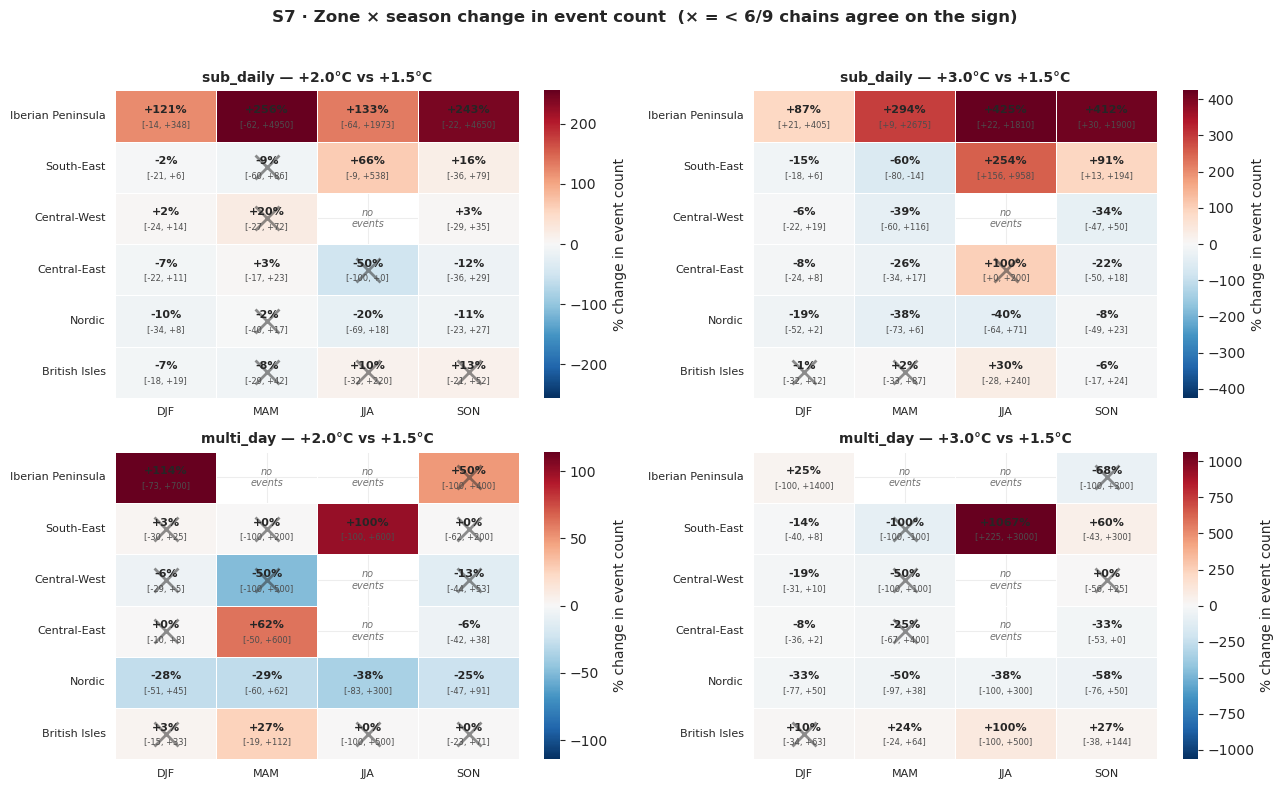

In [11]:
zone_season_change = compute_zone_season_change(events_by_season, zones, SEASON_ORDER,
                                                period_names, spread=SPREAD)
fig = plot_zone_season_change(zone_season_change, STYLE)
fig.savefig(FIGS / "S12_zone_season_change.png", dpi=200, bbox_inches="tight")
plt.show()

## S13 · Significance — Wilcoxon signed-rank across the 9 chains

Paired, two-sided Wilcoxon test on the per-chain event counts, plus the fraction of chains agreeing on
the sign. **The southern sub-daily increase is the robust, significant result; most multi-day shifts
are not significant at n = 9** — and the paper says so rather than leaving it to be discovered.

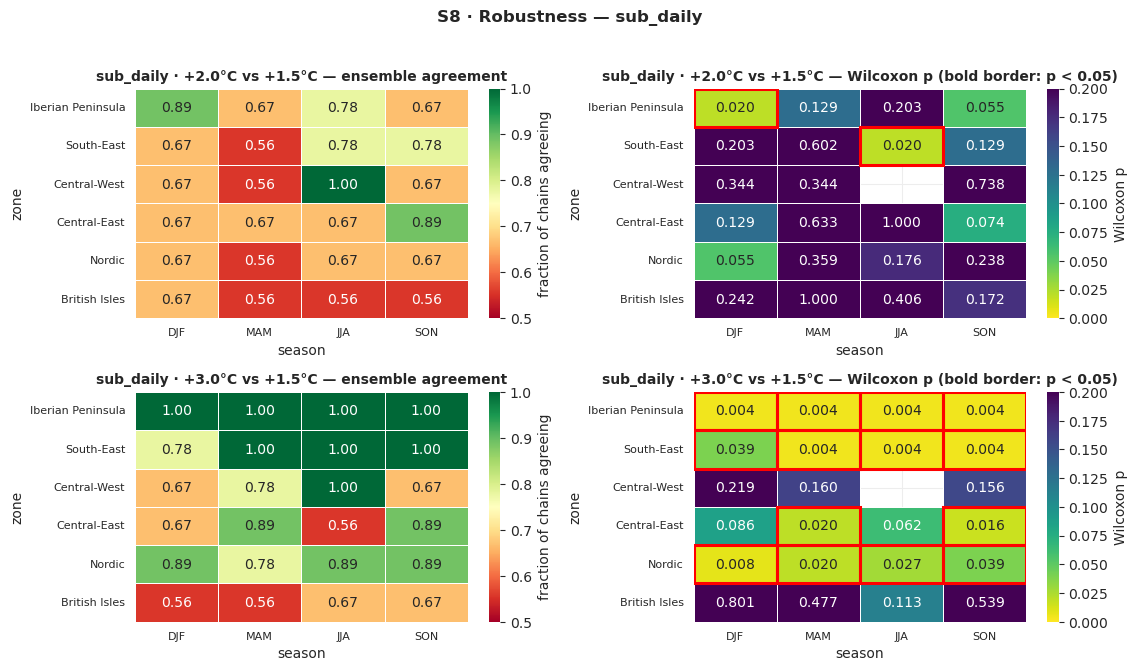

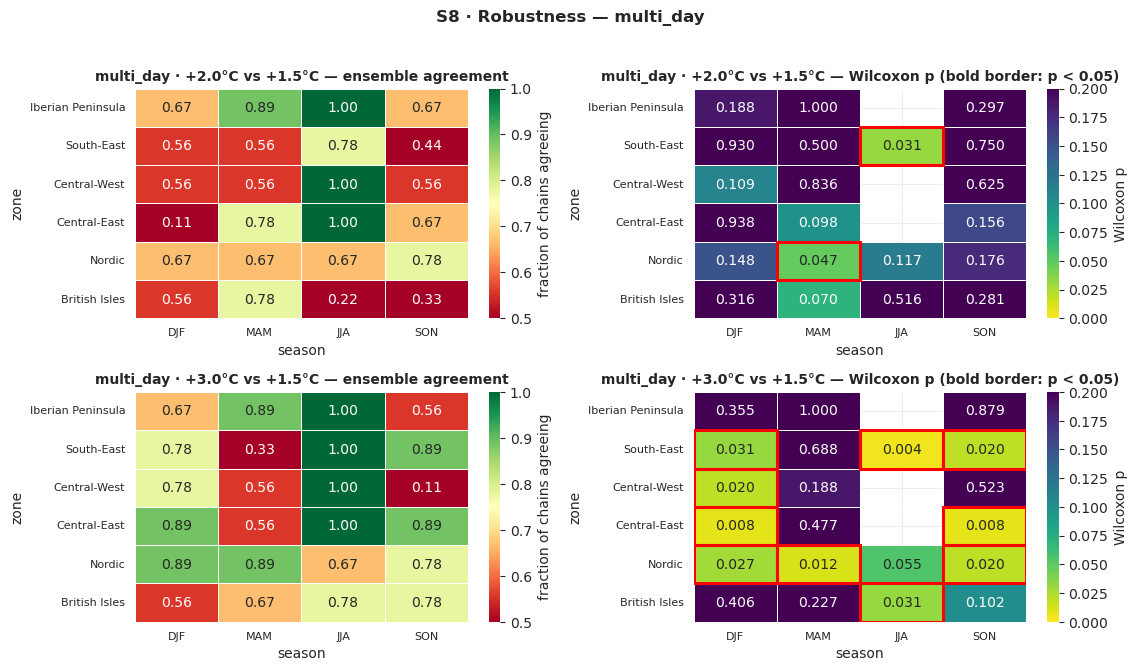

In [12]:
significance = compute_event_significance(events_by_season, zones, SEASON_ORDER, period_names)
for duration_class in DURATION_BINS:
    fig = plot_significance(significance, duration_class, STYLE)
    fig.savefig(FIGS / f"S13_significance_{duration_class}.png", dpi=200, bbox_inches="tight")
    plt.show()

# The SAME callables Figs 3c and 4c are drawn with — so this figure cannot drift away from them.
def sub_daily_attribution(zone, season):
    return attribution_change_by_model(evening_peak_components, zone, season,
                                       REFERENCE, WARMEST, STYLE.drivers)

def multi_day_attribution(zone, season):
    return attribution_change_by_model(multi_day_events, zone, season, REFERENCE, WARMEST,
                                       STYLE.drivers, column_template="{season}_{driver}",
                                       net_column="{season}_RL")

for name, attribution, panel in [("sub_daily", sub_daily_attribution, "3c"),
                                 ("multi_day", multi_day_attribution, "4c")]:
    fig = plot_driver_attribution_spread(
        attribution, ["DJF", "JJA"], STYLE,
        title=f"S14 · Per-driver attribution spread — {name} events (the spread behind Fig {panel})")
    fig.savefig(FIGS / f"S14_attribution_spread_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

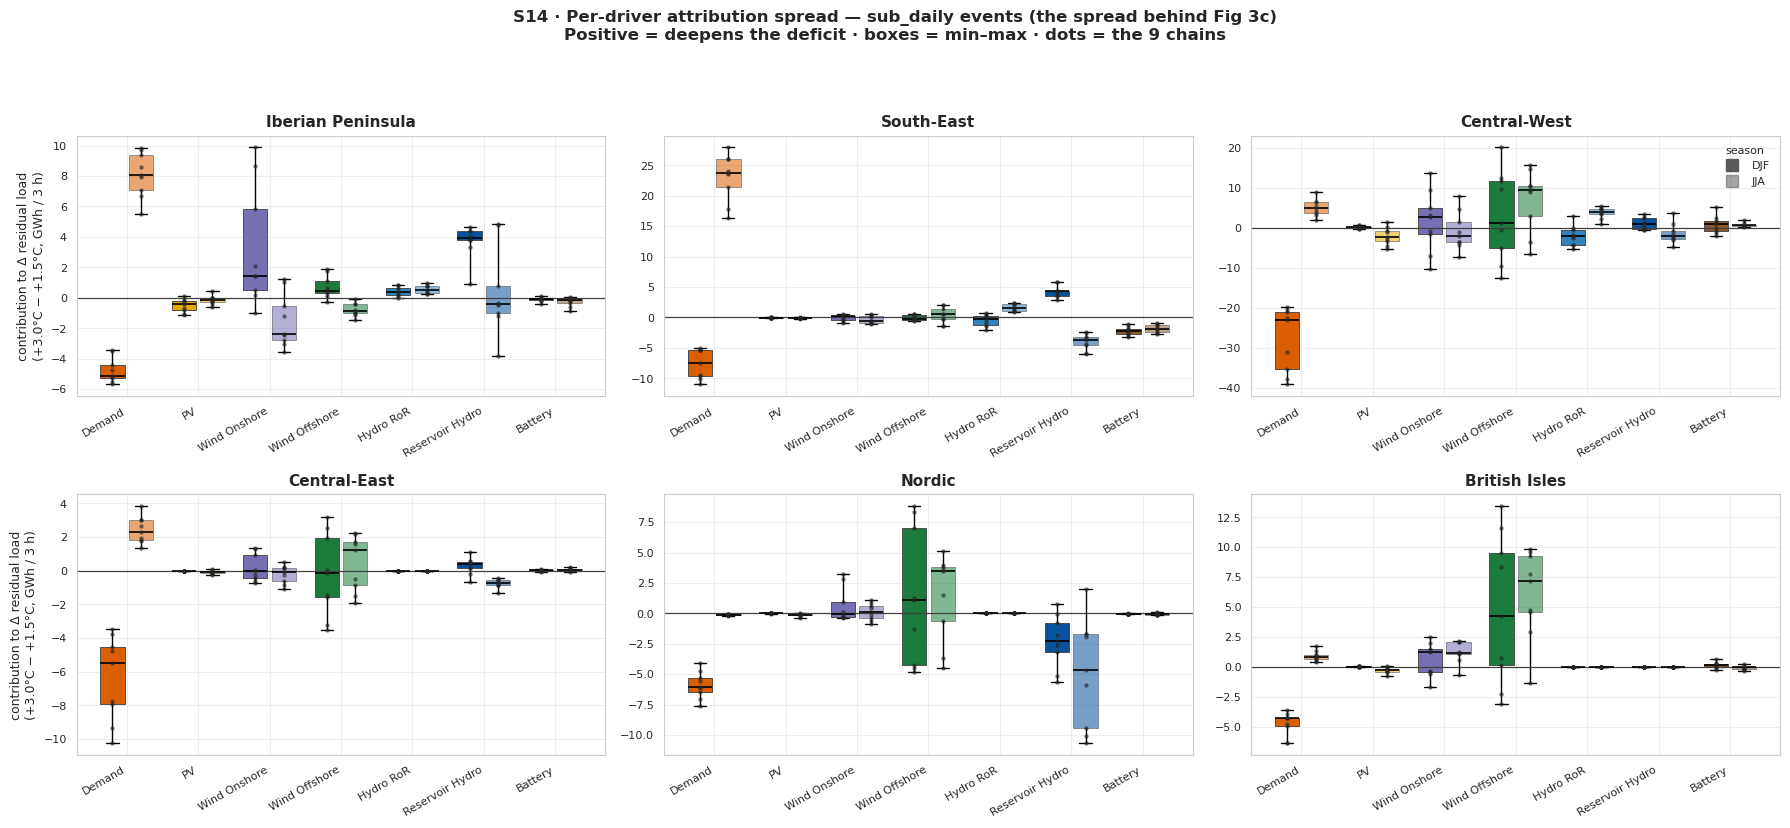

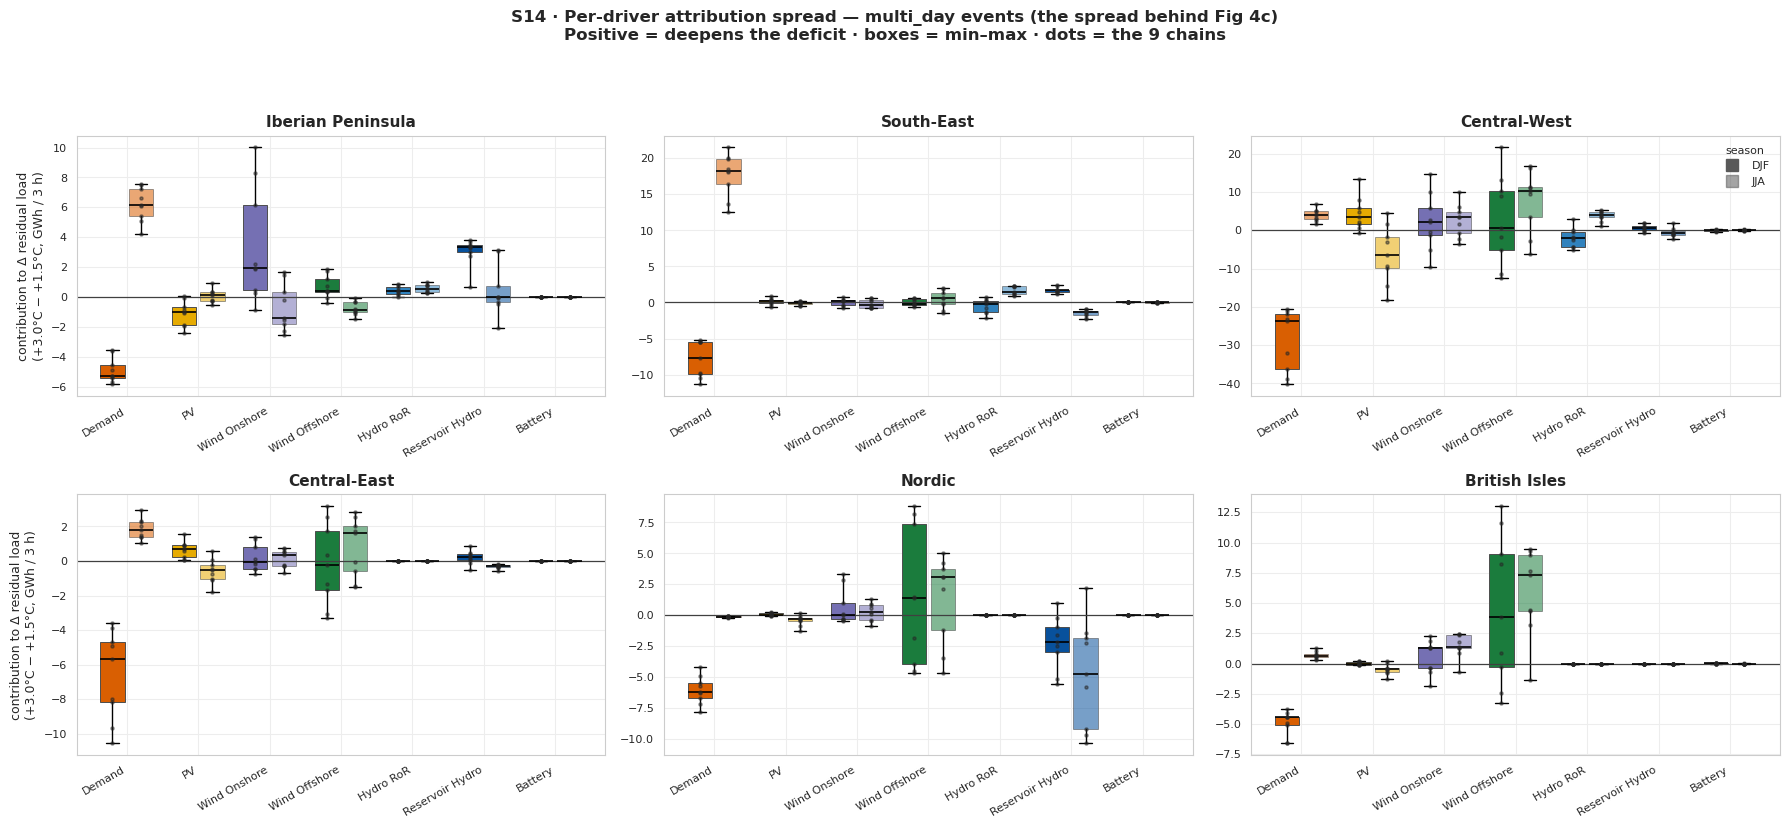

In [13]:
# The SAME callables Figs 3c and 4c are drawn with — so this figure cannot drift away from them.
def sub_daily_attribution(zone, season):
    return attribution_change_by_model(evening_peak_components, zone, season,
                                       REFERENCE, WARMEST, STYLE.drivers)

def multi_day_attribution(zone, season):
    return attribution_change_by_model(multi_day_events, zone, season, REFERENCE, WARMEST,
                                       STYLE.drivers, column_template="{season}_{driver}",
                                       net_column="{season}_RL")

for name, attribution, panel in [("sub_daily", sub_daily_attribution, "3c"),
                                 ("multi_day", multi_day_attribution, "4c")]:
    fig = plot_driver_attribution_spread(
        attribution, ["DJF", "JJA"], STYLE,
        title=f"S14 · Per-driver attribution spread — {name} events (the spread behind Fig {panel})")
    fig.savefig(FIGS / f"S14_attribution_spread_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## S15 · Diurnal event profiles

The mechanism claim of Fig 3: southern sub-daily events are **evening** events — the hours after the PV
cliff, when cooling demand has not yet fallen. If the sub-daily events did not cluster in the evening,
that story would be wrong.

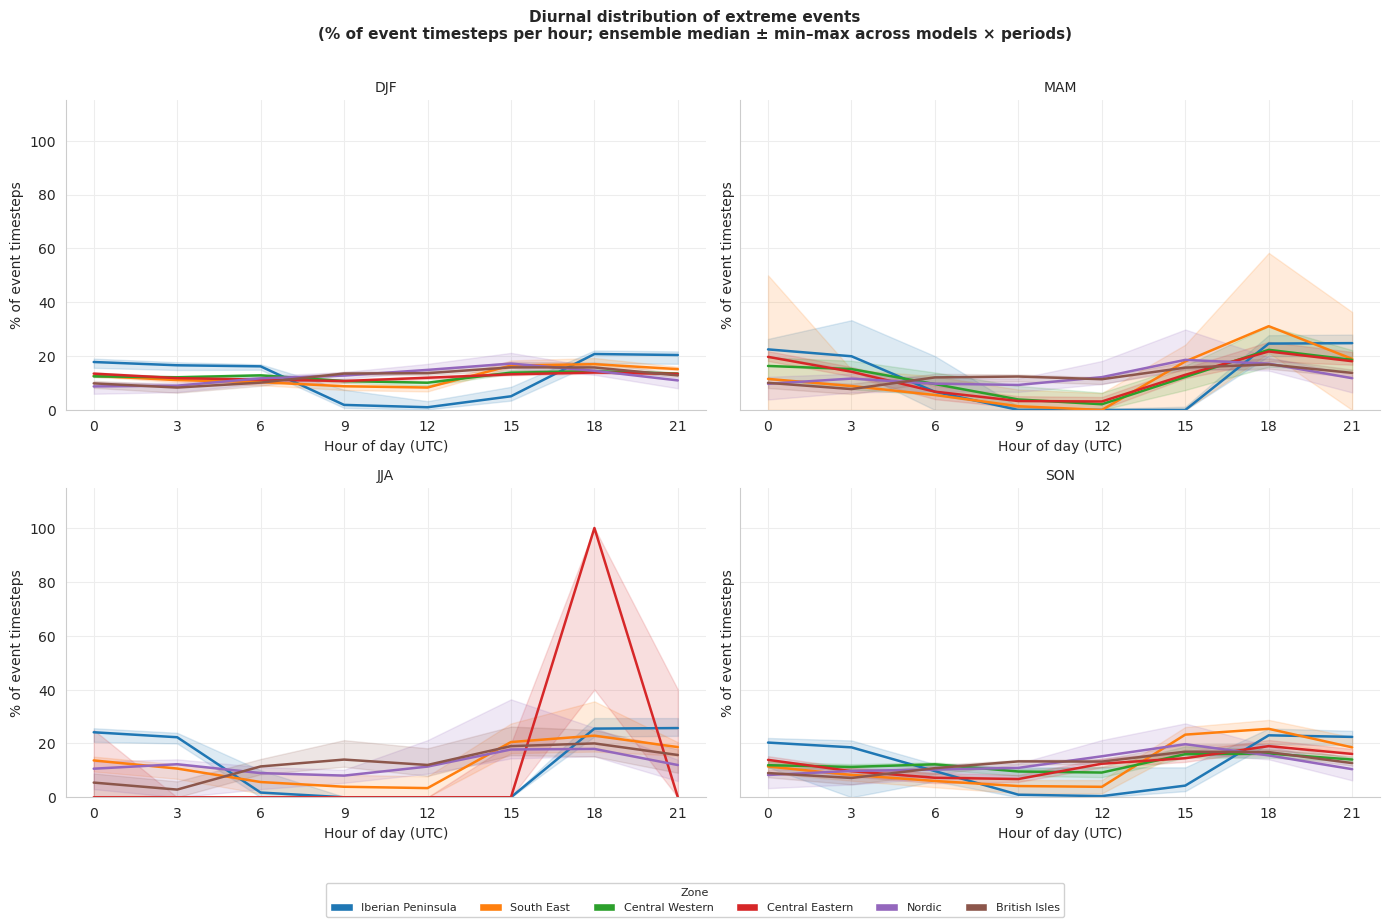

In [14]:
diurnal = extract_event_diurnal_profiles(
    main["residual_load"], main["components"],
    {m: zone_threshold_by_season for m in models}, period_defs, models, zones,
    SEASON_ORDER, SEASON_MONTHS, method=EVENT_DETECTION)

plot_event_diurnal_profile(
    diurnal, zones, SEASON_ORDER, period_defs=period_defs,
    period_colors=dict(zip(period_names, GWL_COLORS)), spread=SPREAD,
    path_savefig=FIGS / "S15_event_diurnal_profile.png")

fig = plot_level_vs_persistence(multi_day_events, STYLE)
fig.savefig(FIGS / "S16_level_vs_persistence.png", dpi=200, bbox_inches="tight")
plt.show()

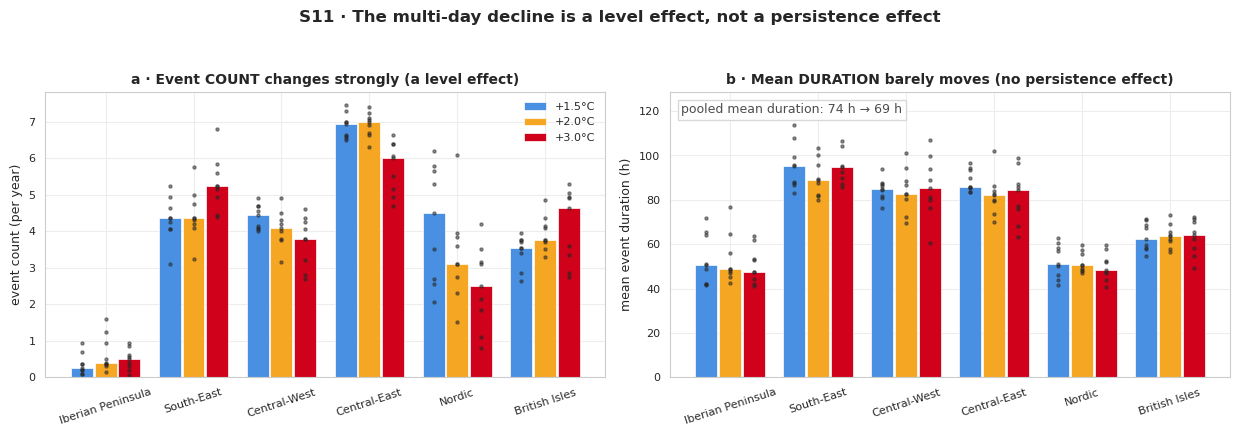

In [15]:
fig = plot_level_vs_persistence(multi_day_events, STYLE)
fig.savefig(FIGS / "S16_level_vs_persistence.png", dpi=200, bbox_inches="tight")
plt.show()

## S17 · Compound risk — zone-pair co-occurrence by duration class

**Multi-day events are spatially coherent across zones** — a systemic, compound risk that no single
zone's interconnectors can help with — whereas sub-daily events stay zone-local. The ±24 h window is
passed explicitly; the global config is never mutated.

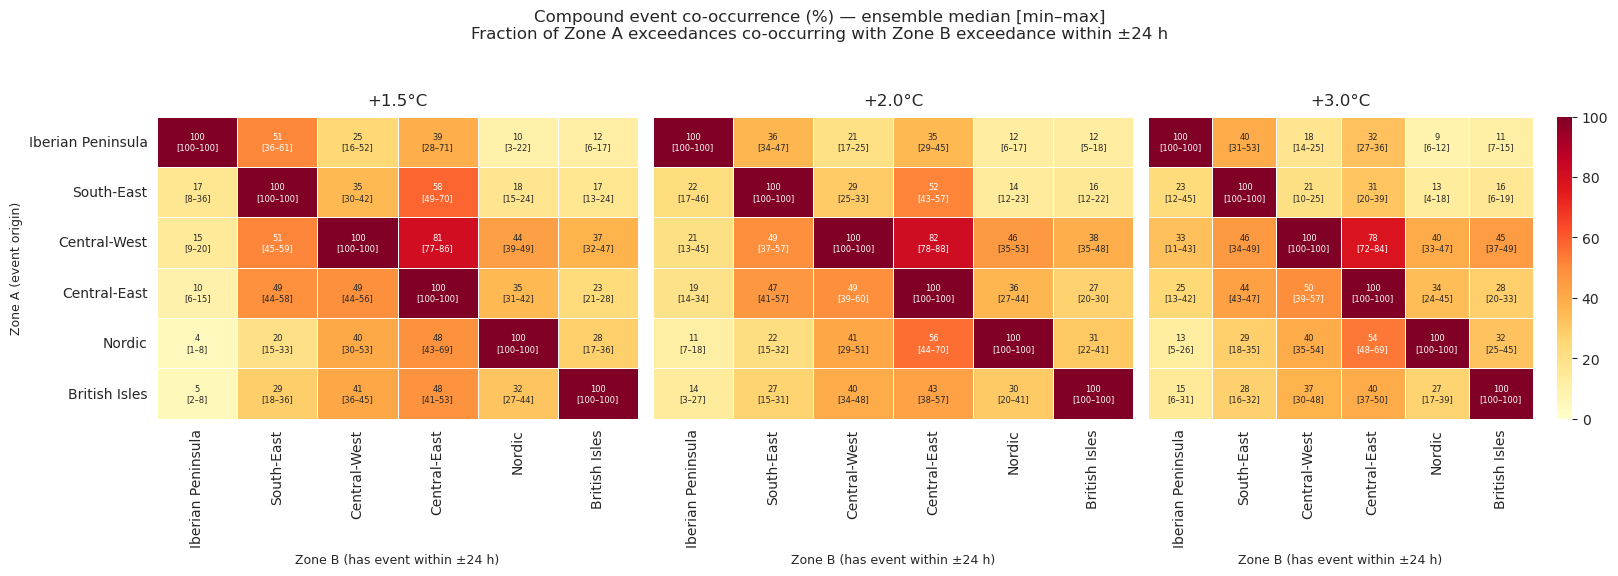

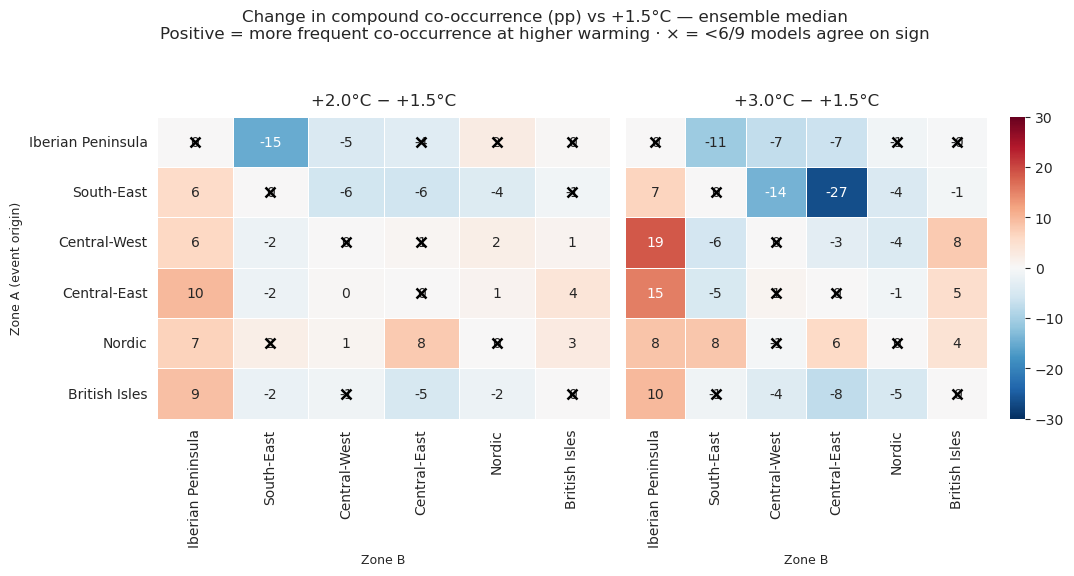

sub_daily: saved 0 figure(s)


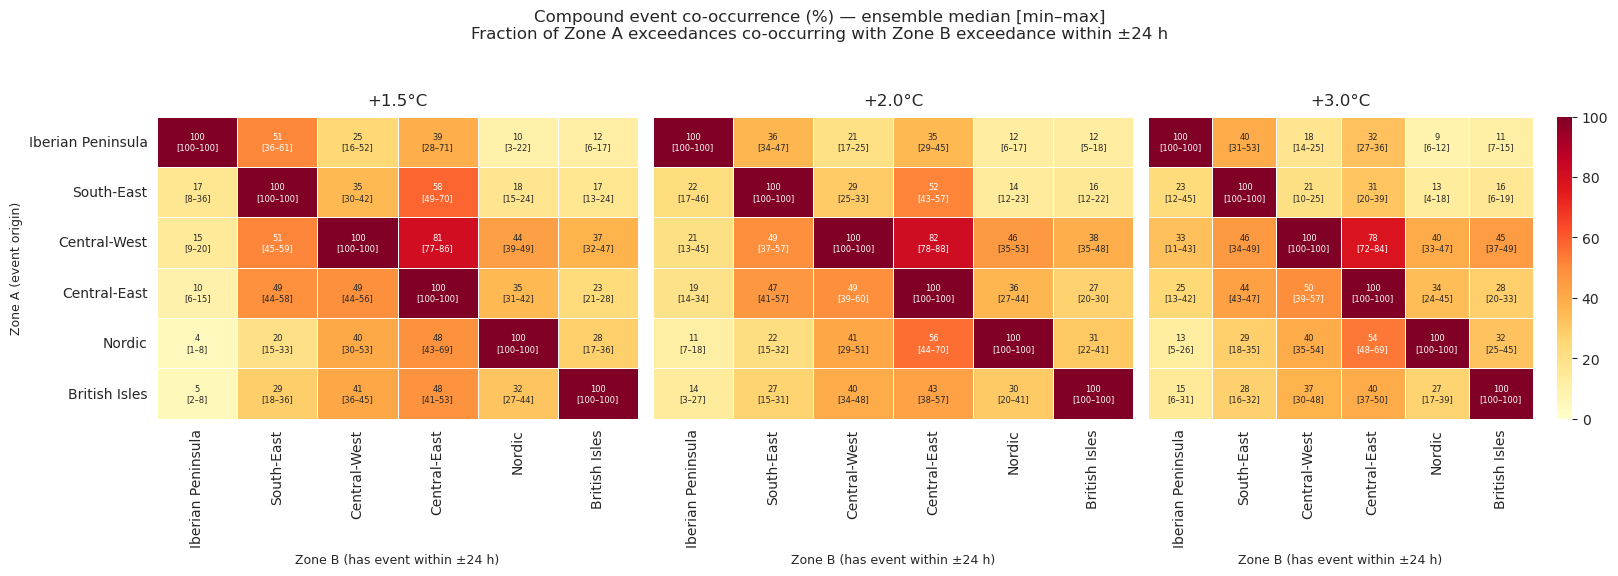

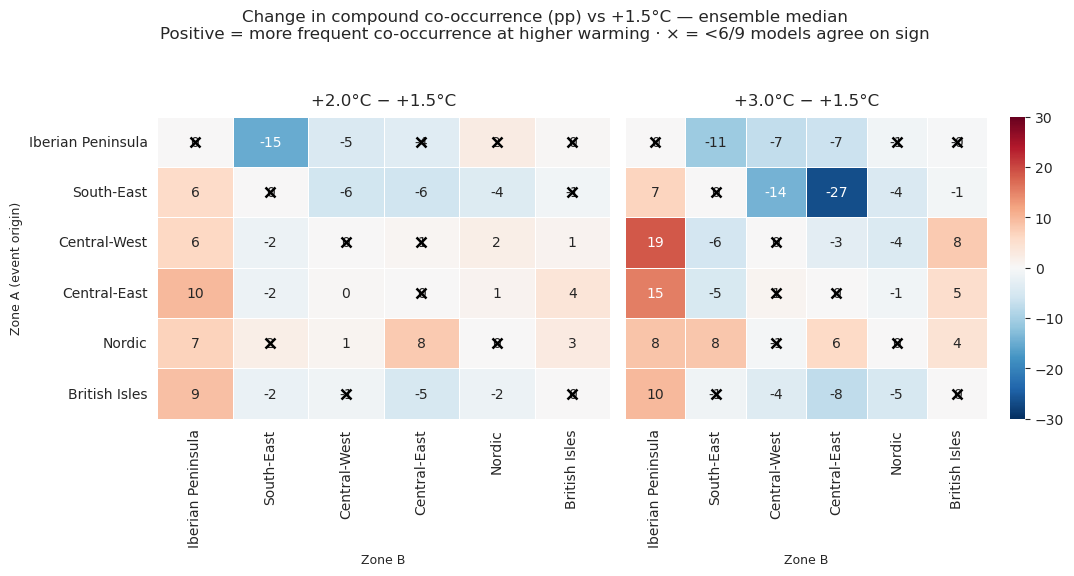

multi_day: saved 0 figure(s)


In [16]:
for duration_class in DURATION_BINS:
    cooccurrence = compute_zone_pair_cooccurrence_by_duration(
        main["residual_load"], main["threshold_by_model"], period_defs, models, zones,
        duration_bins={duration_class: DURATION_BINS[duration_class]},
        window_steps=COOCCURRENCE_WINDOW_STEPS)

    figures = plot_cooccurrence(cooccurrence, period_defs, STYLE, duration_class,
                                window_steps=COOCCURRENCE_WINDOW_STEPS)
    for n, fig in enumerate(figures):
        suffix = "" if len(figures) == 1 else f"_{n}"
        fig.savefig(FIGS / f"S17_cooccurrence_{duration_class}{suffix}.png",
                    dpi=200, bbox_inches="tight")
    print(f"{duration_class}: saved {len(figures)} figure(s)")
    plt.show()

## S18 · Unserved energy — the operator-relevant metric

An event count is a climate statistic. **Unserved energy** — the share of demand the modelled system
cannot cover — is what an operator actually plans against, and it weights events by their depth and
duration rather than counting them equally.

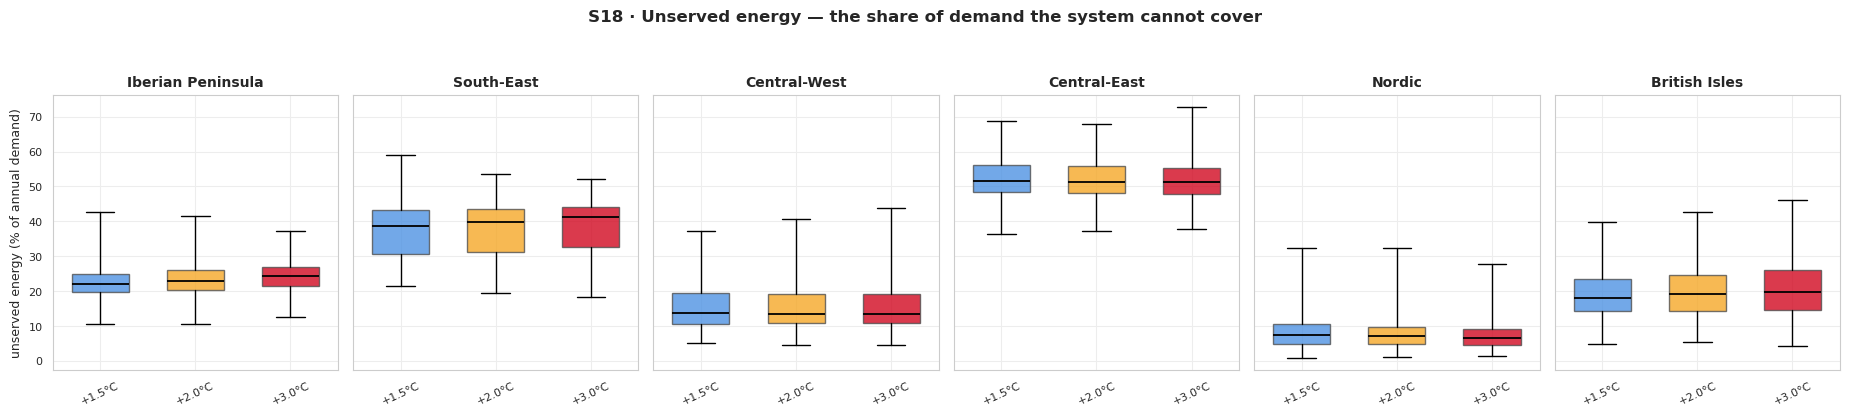

zone               period
British_Isles      +1.5°C    18.160
                   +2.0°C    19.025
                   +3.0°C    19.680
Central_Eastern    +1.5°C    51.660
                   +2.0°C    51.382
                   +3.0°C    51.191
Central_Western    +1.5°C    13.602
                   +2.0°C    13.560
                   +3.0°C    13.297
Iberian_Peninsula  +1.5°C    22.032
                   +2.0°C    22.993
                   +3.0°C    24.209
Nordic             +1.5°C     7.462
                   +2.0°C     7.010
                   +3.0°C     6.545
South_East         +1.5°C    38.728
                   +2.0°C    39.692
                   +3.0°C    41.201


In [17]:
unserved = compute_unserved_energy_fraction(
    main["residual_load"], main["components"], period_defs, models, zones, season_map=SEASON_MAP)

fig, axes = plt.subplots(1, len(zones), figsize=(3.1 * len(zones), 4.2), sharey=True)
q_low, q_high = STYLE.spread_percentiles
for ax, zone in zip(axes, zones):
    data = unserved[unserved.zone == zone]
    per_period = [data[data.period == p]["use_fraction"].values * 100 for p in period_names]
    boxes = ax.boxplot(per_period, positions=range(len(period_names)), widths=0.6,
                       patch_artist=True, showfliers=False, whis=(q_low, q_high),
                       medianprops=dict(color="black", lw=1.3))
    for box, period in zip(boxes["boxes"], period_names):
        box.set_facecolor(STYLE.gwl_colors[period])
        box.set_alpha(0.78)
        box.set_edgecolor("0.3")
    ax.set_xticks(range(len(period_names)))
    ax.set_xticklabels(period_names, fontsize=8, rotation=25)
    ax.set_title(ZONE_LABELS[zone], fontsize=10, fontweight="bold")
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("unserved energy (% of annual demand)", fontsize=9)
fig.suptitle("S18 · Unserved energy — the share of demand the system cannot cover",
             fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIGS / "S18_unserved_energy.png", dpi=200, bbox_inches="tight")
plt.show()

print(unserved.groupby(["zone", "period"])["use_fraction"].median().mul(100).round(3).to_string())

## S19 · Threshold convention — sensitivity to a season-specific p95

Every event in this paper is detected against **one absolute deficit level per zone**, calibrated once
on CERRA and held fixed across seasons and warming levels. The obvious alternative — a
**season-specific** p95 — is tested here.

**It changes no conclusion**, but it cannot be used as the primary convention, because it
**re-baselines each season to its own tail**: it forces ~5 % exceedance in *every* season of the
reference climate *by construction*, which normalises away the very winter→summer migration that is
this paper's central result.

sub_daily: sign agrees in 19/22 populated cells
multi_day: sign agrees in 17/19 populated cells


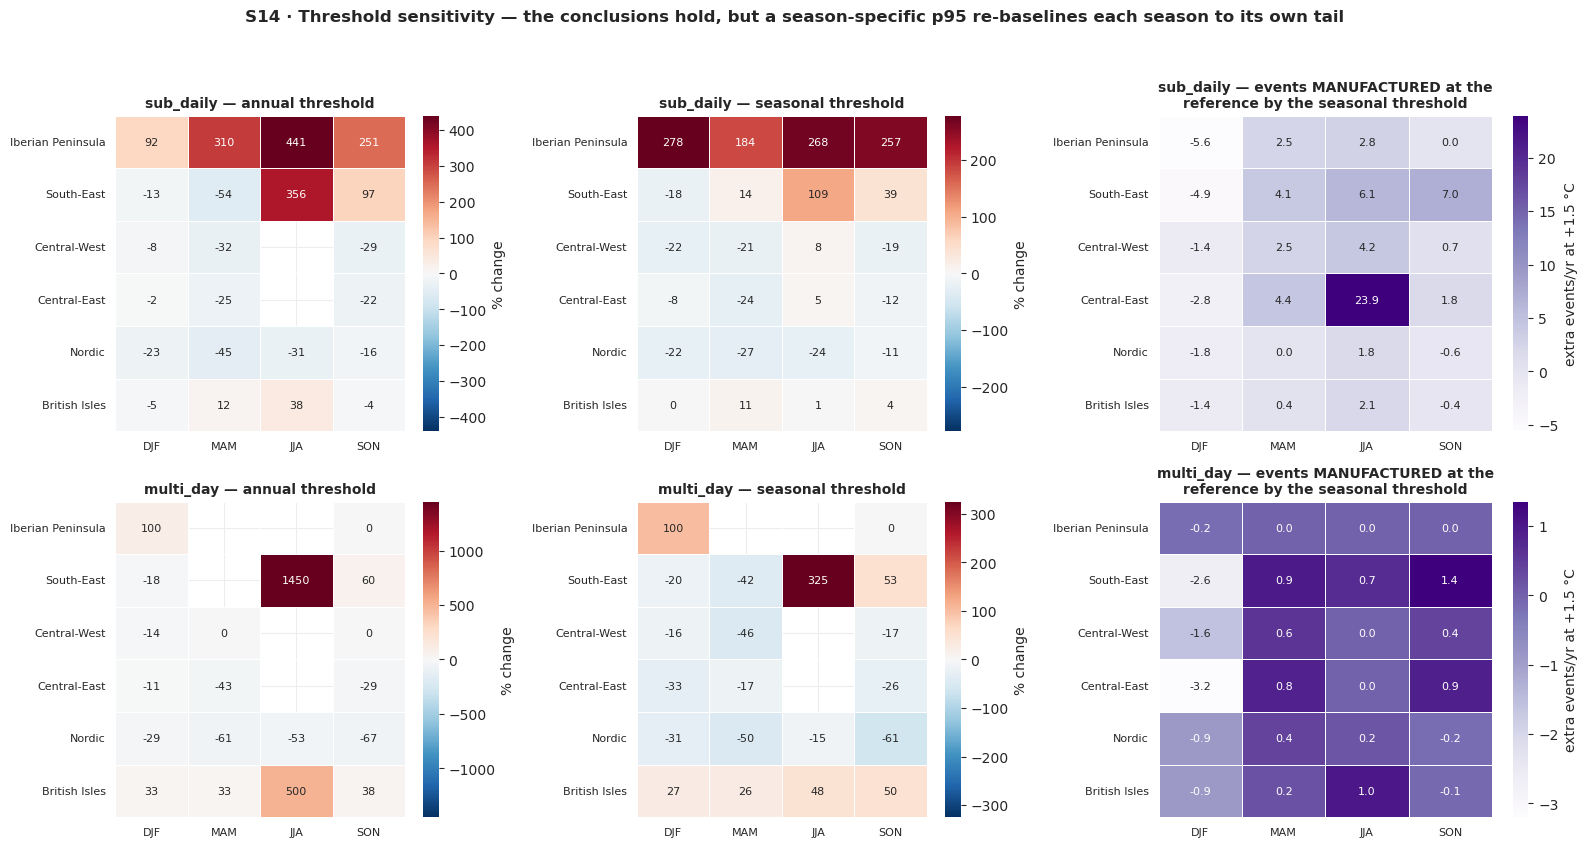

South-East sub-daily events/yr — does summer overtake winter?
  annual    +1.5°C   DJF   12.5  JJA    3.2   -> DJF > JJA
  annual    +3.0°C   DJF   10.9  JJA   14.6   -> JJA > DJF
  seasonal  +1.5°C   DJF    7.6  JJA    9.3   -> JJA > DJF
  seasonal  +3.0°C   DJF    6.2  JJA   19.4   -> JJA > DJF


In [18]:
threshold_sensitivity = compute_threshold_sensitivity(
    main["residual_load"], period_defs, zones, SEASON_ORDER, SEASON_MONTHS,
    zone_threshold, seasonal_thresholds, method=EVENT_DETECTION)

fig = plot_threshold_sensitivity(threshold_sensitivity, STYLE)
fig.savefig(FIGS / "S19_threshold_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

# The headline artifact, in numbers: under each convention, does summer overtake winter?
print("South-East sub-daily events/yr — does summer overtake winter?")
for scheme in ["annual", "seasonal"]:
    rows = threshold_sensitivity[threshold_sensitivity.scheme == scheme]
    rows = rows[rows.zone == "South_East"]
    for period in [REFERENCE, WARMEST]:
        djf = rows[(rows.period == period) & (rows.season == "DJF")]["sub_daily"].median()
        jja = rows[(rows.period == period) & (rows.season == "JJA")]["sub_daily"].median()
        verdict = "JJA > DJF" if jja > djf else "DJF > JJA"
        print(f"  {scheme:<9} {period:<8} DJF {djf:6.1f}  JJA {jja:6.1f}   -> {verdict}")

## S20 · Scenario sensitivity — LOW/2050 vs HIGH/2040

*"Is the southern surge just an artifact of the LOW capacity build-out?"* is the first question a
referee asks. The whole analysis is re-run on **HIGH/2040** — a materially different system, with more
solar and wind and a different battery fleet.

**The threshold is re-calibrated on that scenario's own CERRA pass.** A different build-out is a
different system, so its reference deficit distribution is different too; holding the LOW threshold
fixed would simply record that HIGH/2040 has more capacity, not whether the *climate signal* survives.
What must survive is the **relative** change from +1.5 to +3.0 °C.

The build-outs have very different baselines, so a %-change alone misleads (a near-zero reference
manufactures a huge percentage). The figure therefore shows **absolute** event frequencies (left) *and*
the %-change restricted to cases with a large-enough baseline (right).

HIGH/2040 loaded [39s]


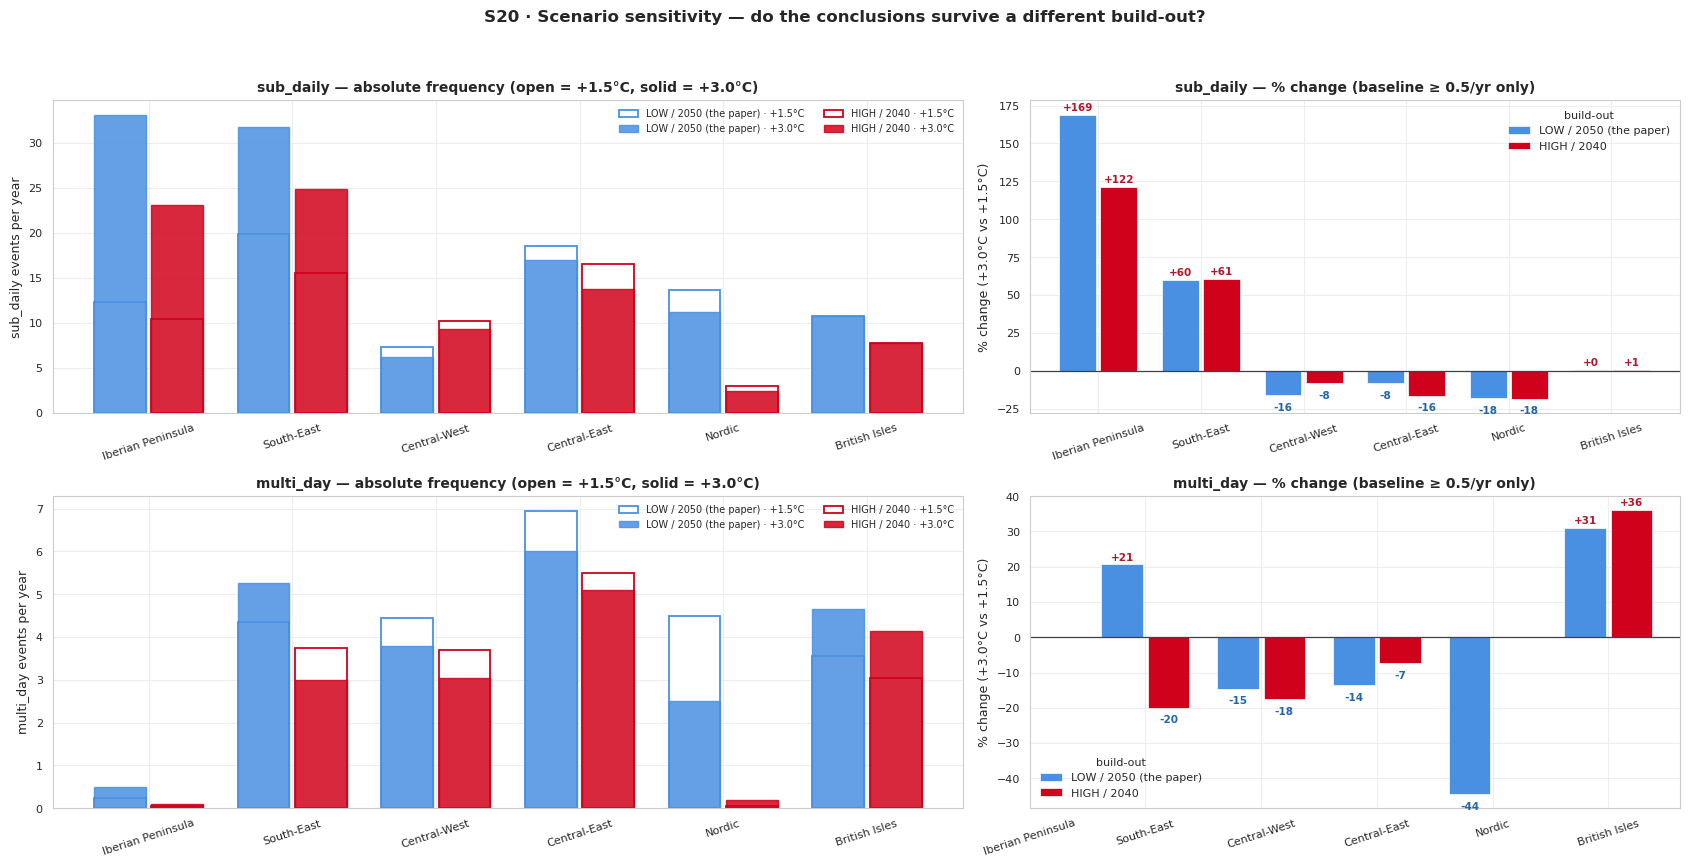

In [19]:
started = time.perf_counter()
high_2040 = load_run(RUN_TAG_HIGH_2040)                      # own CERRA calibration — see above
events_high, _, _ = event_tables(high_2040, period_defs)
print(f"HIGH/2040 loaded [{time.perf_counter() - started:.0f}s]")

fig = plot_scenario_sensitivity(
    {"LOW / 2050 (the paper)": events_annual, "HIGH / 2040": events_high}, STYLE)
fig.savefig(FIGS / "S20_scenario_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

In [20]:
# The headline numbers under both build-outs — absolute frequencies AND % change, side by side, so
# the near-zero-baseline artifacts (e.g. Nordic multi-day) are self-evident.
rows = []
for duration_class in DURATION_BINS:
    for zone in zones:
        row = {"duration": duration_class, "zone": ZONE_LABELS[zone]}
        for label, events in [("LOW/2050", events_annual), ("HIGH/2040", events_high)]:
            data = events[(events.duration_class == duration_class) & (events.zone == zone)]
            ref = data[data.period == REFERENCE]["freq_per_year"].median()
            warm = data[data.period == WARMEST]["freq_per_year"].median()
            row[f"{label} {REFERENCE}"] = round(ref, 2)
            row[f"{label} {WARMEST}"] = round(warm, 2)
            row[f"{label} Δ%"] = round(100 * (warm - ref) / ref, 0) if ref >= 0.5 else np.nan
        rows.append(row)

scenario_comparison = pd.DataFrame(rows)
print("Event frequency (events/yr) and % change, +1.5 -> +3.0 °C, under both build-outs")
print("(Δ% shown only where the reference baseline ≥ 0.5/yr — below that a percentage is noise):")
print(scenario_comparison.to_string(index=False))

# Recommendation: the ABSOLUTE columns are the primary read — the southern sub-daily surge survives
# both build-outs (Iberia/South-East rise in both), while the multi-day differences sit on baselines
# small enough that only the absolute counts are trustworthy.

Event frequency (events/yr) and % change, +1.5 -> +3.0 °C, under both build-outs
(Δ% shown only where the reference baseline ≥ 0.5/yr — below that a percentage is noise):
 duration              zone  LOW/2050 +1.5°C  LOW/2050 +3.0°C  LOW/2050 Δ%  HIGH/2040 +1.5°C  HIGH/2040 +3.0°C  HIGH/2040 Δ%
sub_daily Iberian Peninsula            12.30            33.10        169.0             10.45             23.15         122.0
sub_daily        South-East            19.85            31.80         60.0             15.50             24.90          61.0
sub_daily      Central-West             7.35             6.15        -16.0             10.20              9.35          -8.0
sub_daily      Central-East            18.50            17.00         -8.0             16.50             13.80         -16.0
sub_daily            Nordic            13.65            11.15        -18.0              3.00              2.45         -18.0
sub_daily     British Isles            10.75            10.80          0.0     

## S21 · Flexibility counterfactual — with and without batteries

How much of the deficit do the batteries actually absorb?

The battery-free residual load is reconstructed from the **same sysflex run**, not a second simulation.
In the sysflex scheme the reservoir is dispatched **first and independently**, and only then does the
battery operate on the reservoir-adjusted load; the saved battery dispatch is exactly
`RL_before − RL_after`, so **`RL_no_battery = residual_load + battery_dispatch`** recovers the
pre-battery state with the reservoir dispatch held fixed. This isolates the battery cleanly.

*(A standalone no-battery simulation was checked and rejected: it uses a different reservoir-dispatch
scheme, so its reservoir output differs by up to 100× per zone — Central-East 8 vs 39 TWh/yr, Nordic
175 vs 1 — which would swamp the battery signal being measured. The reconstruction avoids that
entirely.)*

Both series are scored against the same absolute CERRA p95 threshold.

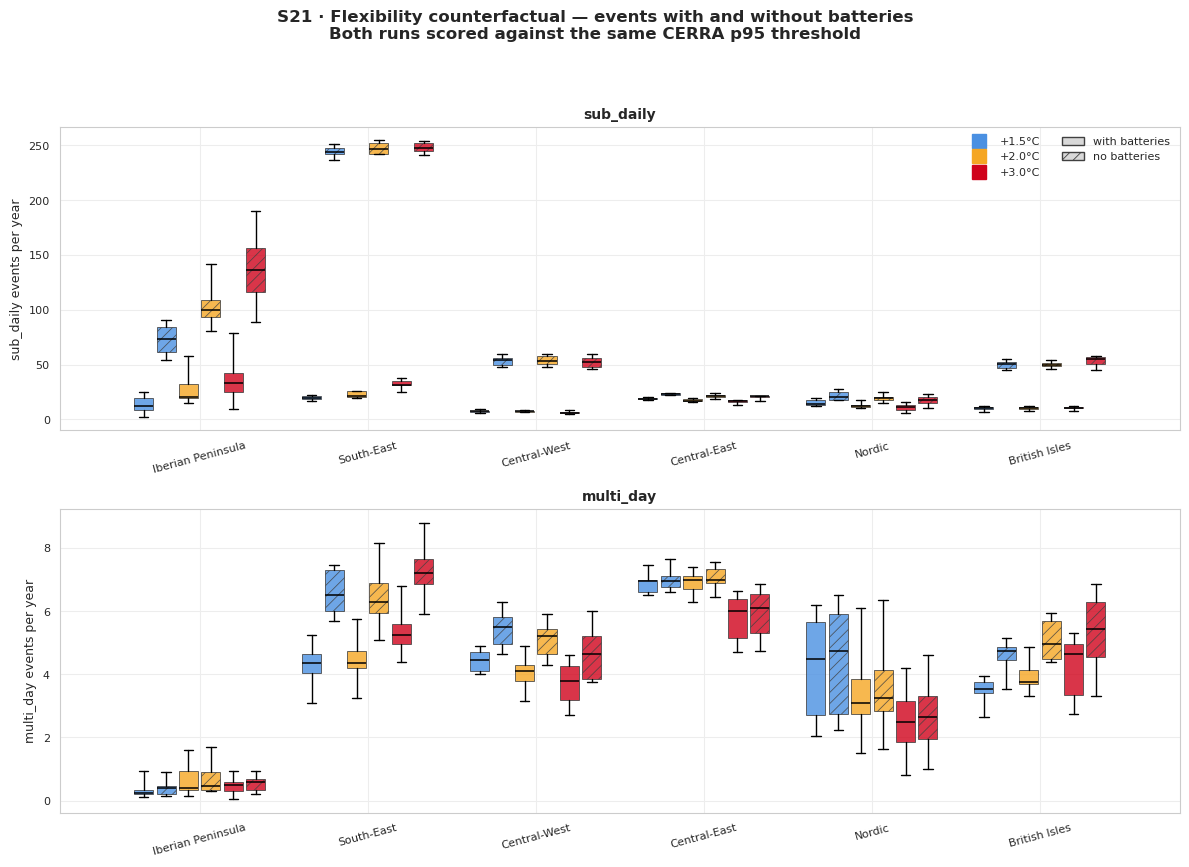


Batteries: events per year with vs without, at +3.0°C (absorbed % only where baseline ≥ 0.5/yr):
 duration              zone  with (+3.0°C)  without (+3.0°C)  absorbed %
sub_daily Iberian Peninsula          33.10            136.25        76.0
sub_daily        South-East          31.80            247.55        87.0
sub_daily      Central-West           6.15             52.20        88.0
sub_daily      Central-East          17.00             21.10        19.0
sub_daily            Nordic          11.15             17.95        38.0
sub_daily     British Isles          10.80             55.60        81.0
multi_day Iberian Peninsula           0.50              0.60        17.0
multi_day        South-East           5.25              7.20        27.0
multi_day      Central-West           3.80              4.65        18.0
multi_day      Central-East           6.00              6.10         2.0
multi_day            Nordic           2.50              2.65         6.0
multi_day     British Isle

In [21]:
# Battery-free residual load from the SAME run (reservoir held fixed): RL + battery_dispatch.
no_battery = remove_batteries(main)
events_no_battery, _, _ = event_tables(no_battery, period_defs)

fig = plot_flexibility_counterfactual(events_annual, events_no_battery, STYLE)
fig.savefig(FIGS / "S21_flexibility_counterfactual.png", dpi=200, bbox_inches="tight")
plt.show()

# Absolute counts (with vs without) AND % absorbed — the % is only meaningful where the no-battery
# baseline is large enough to carry one.
rows = []
for duration_class in DURATION_BINS:
    for zone in zones:
        row = {"duration": duration_class, "zone": ZONE_LABELS[zone]}
        for label, events in [("with", events_annual), ("without", events_no_battery)]:
            data = events[(events.duration_class == duration_class) & (events.zone == zone)
                          & (events.period == WARMEST)]
            row[f"{label} ({WARMEST})"] = round(data["freq_per_year"].median(), 2)
        w, wo = row[f"with ({WARMEST})"], row[f"without ({WARMEST})"]
        row["absorbed %"] = round(100 * (wo - w) / wo, 0) if wo >= 0.5 else np.nan
        rows.append(row)

print("\nBatteries: events per year with vs without, at", WARMEST,
      "(absorbed % only where baseline ≥ 0.5/yr):")
print(pd.DataFrame(rows).to_string(index=False))

## S22 · Wind-turbine sensitivity — does the turbine choice change the conclusions?

Wind power is converted with **one** turbine model, and that choice is consequential: it sets the
capacity factor outright. Three turbines have precomputed capacity factors for all 9 chains + CERRA
(`EUROPE_TURBINES`), spanning a wide range of **specific power** (rated power per swept area) — the
property that governs capacity factor:

| turbine | rotor / rated | specific power | onshore CF | offshore CF |
|---|---|---|---|---|
| E-126/7580 | 126 m / 7.58 MW | 608 W m⁻² | 0.202 | 0.387 |
| **SWT120/3600** — *this paper* | 120 m / 3.60 MW | **318 W m⁻²** | **0.262** | **0.509** |
| SWT142/3150 | 142 m / 3.15 MW | 199 W m⁻² | 0.400 | 0.595 |

**Why SWT120/3600.** Its specific power and capacity factors sit closest to the modern European fleet
(~0.24 onshore, ~0.42 offshore) and to a plausible 2050 machine. E-126/7580's 608 W m⁻² is atypical for
onshore Europe — a high-rated-output design rather than a CF-optimised one — and SWT142/3150's 0.40
onshore CF exceeds any European fleet average.

**The turbine sets the LEVEL, not the SIGNAL.** Switching between them changes zonal wind generation by
+25 % to +92 %, but the *climate signal* — what this paper reports — is nearly turbine-independent:
Δ mean CF over +1.5→+3.0 °C is −1.22 % / −1.10 % / −0.89 % across the three, same sign and magnitude,
with time-series correlations of 0.99 / 0.94.

**Each turbine calibrates its own CERRA p95**, so the threshold moves with it and the level
self-corrects (thresholds drop 8–20 % from E-126 to SWT120). The comparison must therefore be read on
the **relative** +1.5→+3.0 change — exactly as in S20 — which is why the figure shows absolute counts
*and* % change side by side.

**Outcome: every sign is preserved across all three turbines.** The two distinctive results are robust
or strengthen — British Isles multi-day +31 / **+33** / +48 %, South-East sub-daily +60 / **+64** / +75 %.
The one magnitude that is turbine-sensitive is the **Iberian sub-daily surge** (+169 / **+88** / +60 %):
it is demand-driven, so more wind progressively covers the evening cooling peak. Its sign, its rank as
Europe's largest increase, and the north–south dipole are unaffected — but the exact percentage should
be quoted with this range in mind, not on its own.

*The cell below reads the paper's turbine from `RUN_TAG` and loads the other two as the comparison; it
skips cleanly for any run not on disk.*

In [7]:
# The turbine is always the RUN_TAG suffix, so the paper's turbine is read from the tag rather than
# hardcoded — switching RUN_TAG automatically re-points this comparison. The other two are loaded from
# their own folders, each with its own CERRA calibration (a different turbine is a different system).
TURBINE_SUFFIX = {"E-126/7580": "E-126_7580", "SWT120/3600": "SWT120_3600", "SWT142/3150": "SWT142_3150"}

paper_turbine = next((label for label, suffix in TURBINE_SUFFIX.items()
                      if RUN_TAG.endswith(suffix)), None)
if paper_turbine is None:
    raise ValueError(f"RUN_TAG does not end in a known turbine: {RUN_TAG}")
TURBINE_RUNS = {label: RUN_TAG.replace(TURBINE_SUFFIX[paper_turbine], suffix)
                for label, suffix in TURBINE_SUFFIX.items() if label != paper_turbine}
print(f"paper turbine (read from RUN_TAG): {paper_turbine}")
print(f"comparison turbines: {list(TURBINE_RUNS)}\n")


def turbine_run_available(tag: str) -> bool:
    """A run is usable only with all 9 chains AND its own CERRA pass (which sets its threshold)."""
    chains = sum((folder / tag / "residual_load_zonal.nc").exists()
                 for folder in PATH_RESIDUAL_LOAD.glob(f"*_{CLIMATE_SCENARIO}"))
    return chains == len(models) and (PATH_RESIDUAL_LOAD / "cerra" / tag / "residual_load_zonal.nc").exists()


events_by_turbine = {f"{paper_turbine} (the paper)": events_annual}
turbine_thresholds = {f"{paper_turbine} (the paper)": zone_threshold}
for label, tag in TURBINE_RUNS.items():
    if not turbine_run_available(tag):
        print(f"[skip {label}: run not on disk — set turbine=\"{label}\" in "
              f"scripts/run_tyndp_projections_all_models.sh and re-run (9 chains + CERRA)]")
        continue
    started = time.perf_counter()
    run = load_run(tag)                     # own CERRA calibration — see above
    assert len(run["models"]) == len(models), f"{label}: {len(run['models'])}/{len(models)} chains"
    events_by_turbine[label], _, _ = event_tables(run, period_defs)
    turbine_thresholds[label] = run["threshold"]
    print(f"{label}: loaded [{time.perf_counter() - started:.0f}s]")

print(f"\nturbines available: {list(events_by_turbine)}")
print("\nCERRA p95 threshold per zone (GWh/3h) — each turbine calibrates its own:")
print(pd.DataFrame({lab: {ZONE_LABELS[z]: round(float(thr.sel(zone=z)), 1) for z in zones}
                    for lab, thr in turbine_thresholds.items()}).to_string())

SWT120/3600: loaded, threshold(British_Isles) = 146.4 GWh/3h [20s]
SWT142/3150: loaded, threshold(British_Isles) = 123.4 GWh/3h [19s]

turbines available: ['E-126/7580 (the paper)', 'SWT120/3600', 'SWT142/3150']


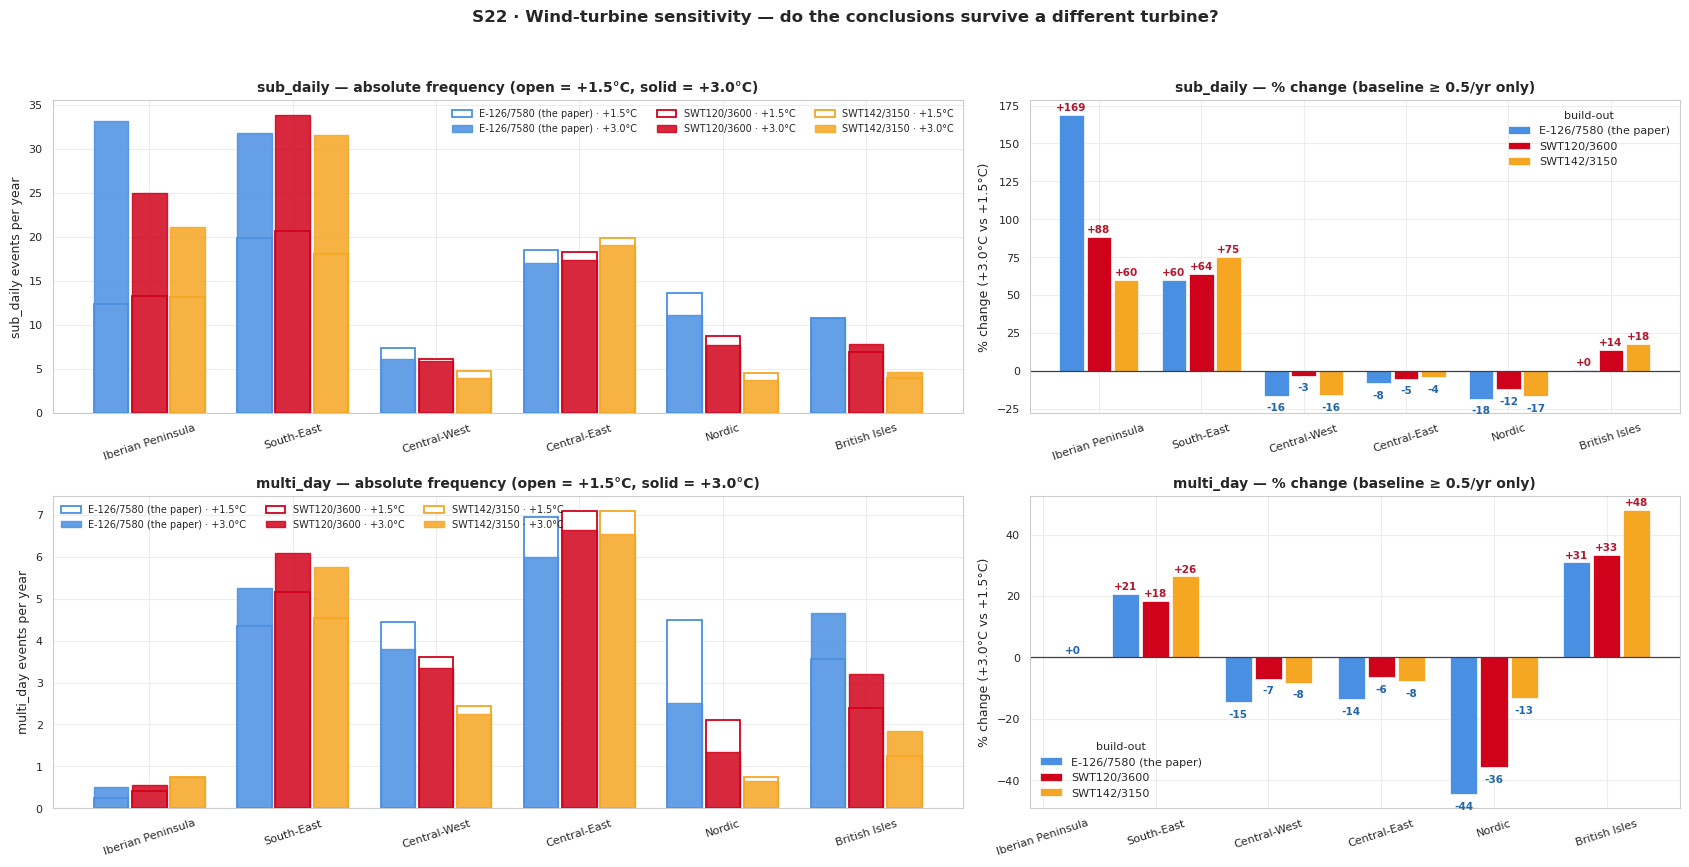

Event frequency and % change, +1.5 -> +3.0 °C, per turbine
(Δ% only where the reference baseline ≥ 0.5/yr):
 duration              zone  E-126/7580 (the paper) ref  E-126/7580 (the paper) Δ%  SWT120/3600 ref  SWT120/3600 Δ%  SWT142/3150 ref  SWT142/3150 Δ%
sub_daily Iberian Peninsula                       12.30                      169.0            13.25            88.0            13.20            60.0
sub_daily        South-East                       19.85                       60.0            20.60            64.0            18.05            75.0
sub_daily      Central-West                        7.35                      -16.0             6.05            -3.0             4.70           -16.0
sub_daily      Central-East                       18.50                       -8.0            18.25            -5.0            19.90            -4.0
sub_daily            Nordic                       13.65                      -18.0             8.75           -12.0             4.50           -17.

In [8]:
if len(events_by_turbine) > 1:
    fig = plot_scenario_sensitivity(
        events_by_turbine, STYLE,
        title="S22 · Wind-turbine sensitivity — do the conclusions survive a different turbine?")
    fig.savefig(FIGS / "S22_turbine_sensitivity.png", dpi=200, bbox_inches="tight")
    plt.show()

    # The two headline claims under test, per turbine, reported as they come out.
    rows = []
    for duration_class in DURATION_BINS:
        for zone in zones:
            row = {"duration": duration_class, "zone": ZONE_LABELS[zone]}
            for label, events in events_by_turbine.items():
                data = events[(events.duration_class == duration_class) & (events.zone == zone)]
                ref = data[data.period == REFERENCE]["freq_per_year"].median()
                warm = data[data.period == WARMEST]["freq_per_year"].median()
                row[f"{label} ref"] = round(ref, 2)
                row[f"{label} Δ%"] = round(100 * (warm - ref) / ref, 0) if ref >= 0.5 else np.nan
            rows.append(row)
    print("Event frequency and % change, +1.5 -> +3.0 °C, per turbine")
    print("(Δ% only where the reference baseline ≥ 0.5/yr):")
    print(pd.DataFrame(rows).to_string(index=False))
else:
    print("Only the paper's turbine is available — nothing to compare yet.")

## S23 · Reservoir operation over the year

How the reservoir fleet actually runs, day by day. Two views, because they answer different questions
and need different encodings:

* **(a) Storage** — the seasonal state. Smooth and strongly seasonal, so **every chain-year is drawn**
  (spaghetti) with the bold mean on top: the thin lines are the genuine inter-annual envelope.
* **(b) Dispatch** — the seasonal *decision*. This carries day-to-day weather noise, so spaghetti
  collapses into a solid block and whichever warming level is drawn last hides the others. It is shown
  as a **median + P10–P90 band** (7-day smoothed) instead — same information about spread, three
  legible warming levels.

Country level: only **10 countries** have a reservoir fleet, and those fleets are strongly
country-specific (Norway dominates the continent), so aggregating would hide the story.

10 countries with a reservoir fleet: AT, BG, CH, ES, FR, IT, NO, PT, RO, SE


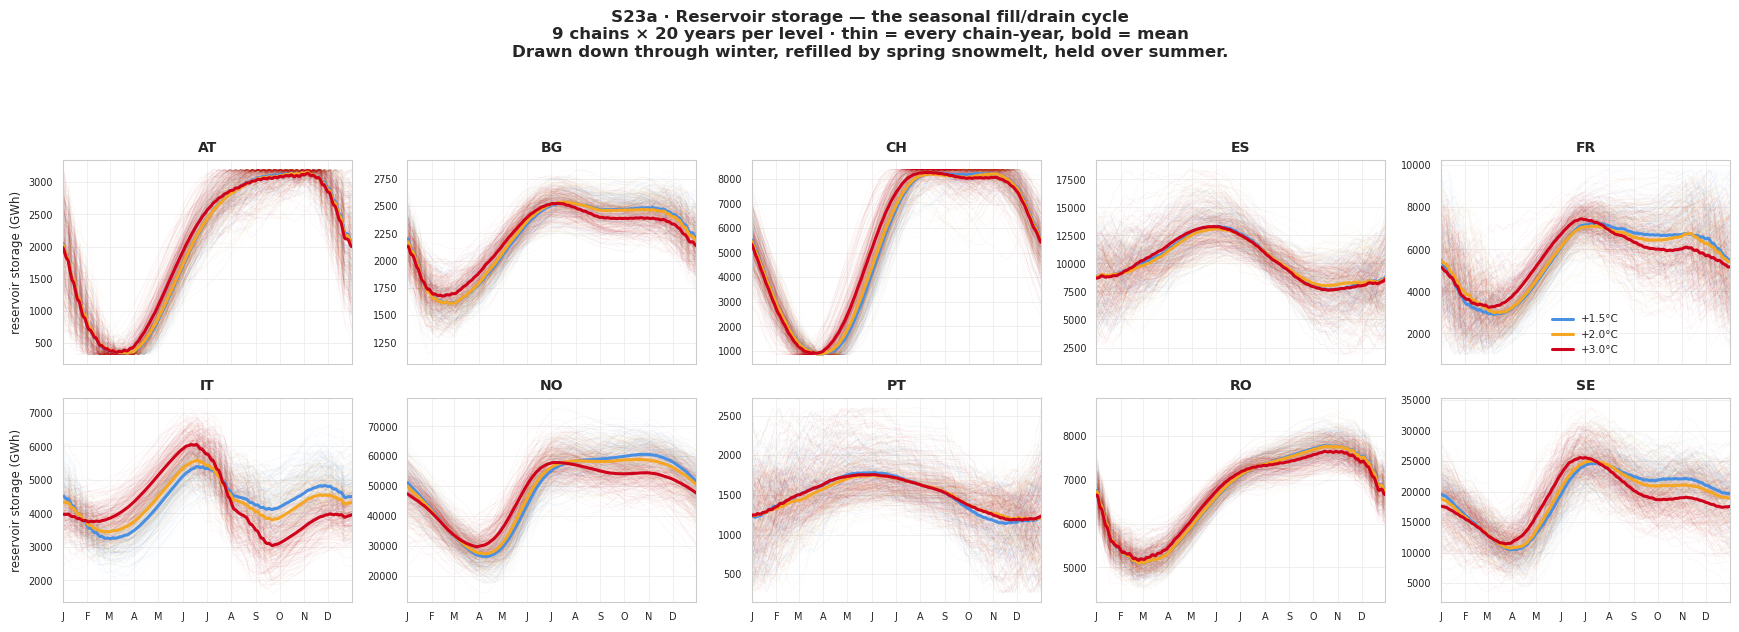

In [24]:
# Country-level components for the reservoir fleet (zonal would hide Norway's dominance).
country_components = {
    m: xr.open_dataset(PATH_RESIDUAL_LOAD / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG / "components.nc")
    for m in models
}
# Only countries that actually operate a reservoir — the rest are structural zeros.
_probe = country_components[models[0]]
RESERVOIR_COUNTRIES = [str(c) for c in _probe["country"].values
                       if float(_probe["reservoir_dispatch_gwh"].sel(country=c).sum()) > 0]
print(f"{len(RESERVOIR_COUNTRIES)} countries with a reservoir fleet: {', '.join(RESERVOIR_COUNTRIES)}")

def operation_curves(components, variable, dim, keys, mode, smooth_days=7):
    """{key: {period: (n_chain_years, 365)}} — the day-of-year curves each panel is drawn from."""
    return {
        k: {p: compute_annual_operation_curves(components, period_defs, p, variable, {dim: k},
                                               mode=mode, smooth_days=smooth_days)
            for p in period_names}
        for k in keys
    }

# (a) storage — smooth + strongly seasonal, so spaghetti earns its place here
storage = operation_curves(country_components, "reservoir_storage_gwh", "country",
                           RESERVOIR_COUNTRIES, mode="mean", smooth_days=1)
fig = plot_seasonal_operation(
    storage, STYLE, mode="spaghetti", ncols=5, ylabel="reservoir storage (GWh)",
    title="S23a · Reservoir storage — the seasonal fill/drain cycle",
    caption="Drawn down through winter, refilled by spring snowmelt, held over summer.")
fig.savefig(FIGS / "S23a_reservoir_storage.png", dpi=200, bbox_inches="tight")
plt.show()

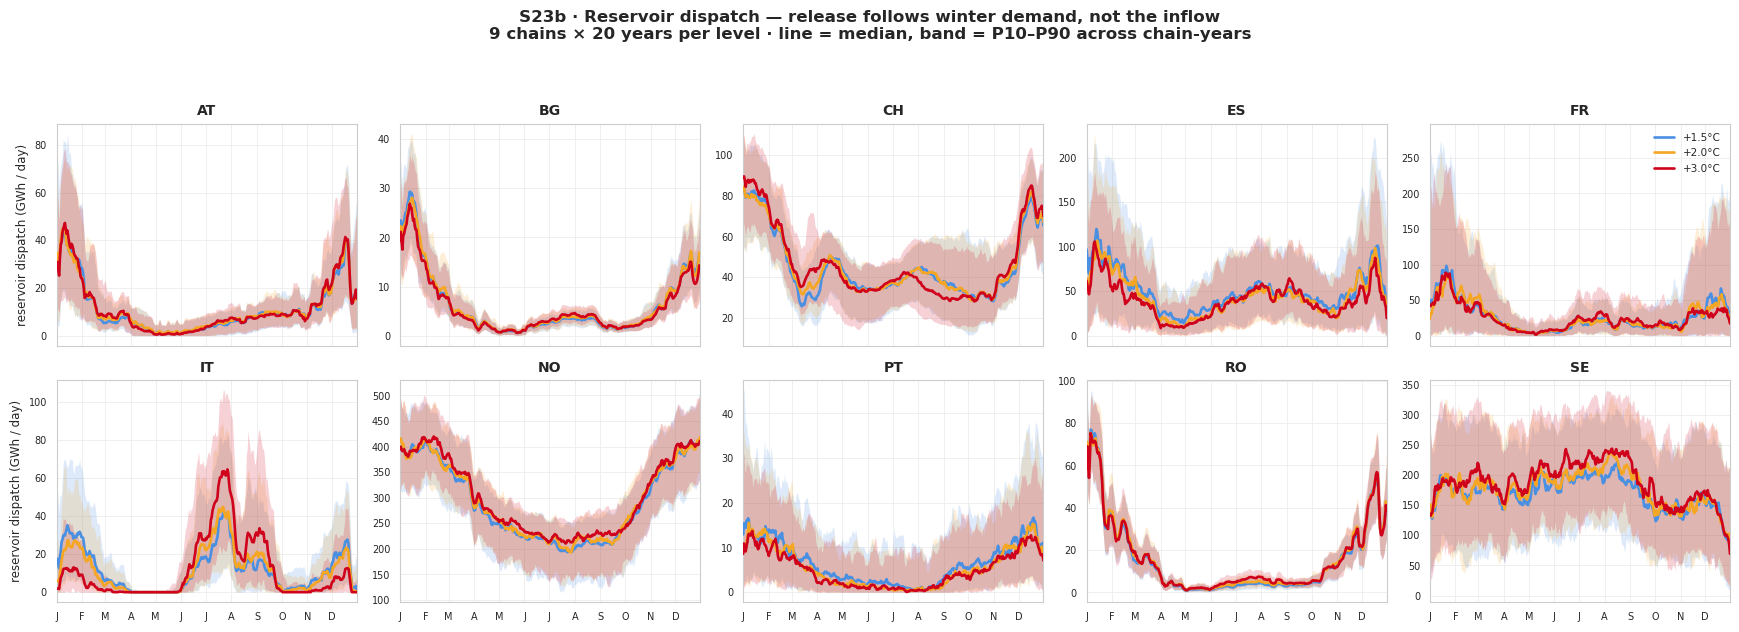

In [25]:
# (b) dispatch — carries weather noise, so a band rather than spaghetti
dispatch = operation_curves(country_components, "reservoir_dispatch_gwh", "country",
                            RESERVOIR_COUNTRIES, mode="sum")
fig = plot_seasonal_operation(
    dispatch, STYLE, mode="band", ncols=5, ylabel="reservoir dispatch (GWh / day)",
    title="S23b · Reservoir dispatch — release follows winter demand, not the inflow")
fig.savefig(FIGS / "S23b_reservoir_dispatch.png", dpi=200, bbox_inches="tight")
plt.show()

## S24 · Battery operation over the year

**Throughput, not net dispatch.** A battery's *net* daily dispatch is not its operation — it is the
round-trip loss: the fleet cycles ~412 GWh/day and nets ~−69 GWh/day, which is just 412 × (1 − 0.85).
Plotting it would look like a result and mean nothing. **Energy cycled per day** (`Σ|dispatch|/2`) is
what shows how hard the battery works, and it has a clear seasonal cycle — roughly doubling from winter
to summer as PV arbitrage takes over.

Shown **per balancing zone**, not per country: 25 of 35 countries operate batteries, the paper's whole
event analysis is zonal, and neighbouring countries in a zone share almost the same diurnal PV cycle.

*Caveat: under `sysflex` the battery is dispatched **per country**, so a zonal curve is the sum of
independent country optimisations, not a zone-wide co-optimisation.*

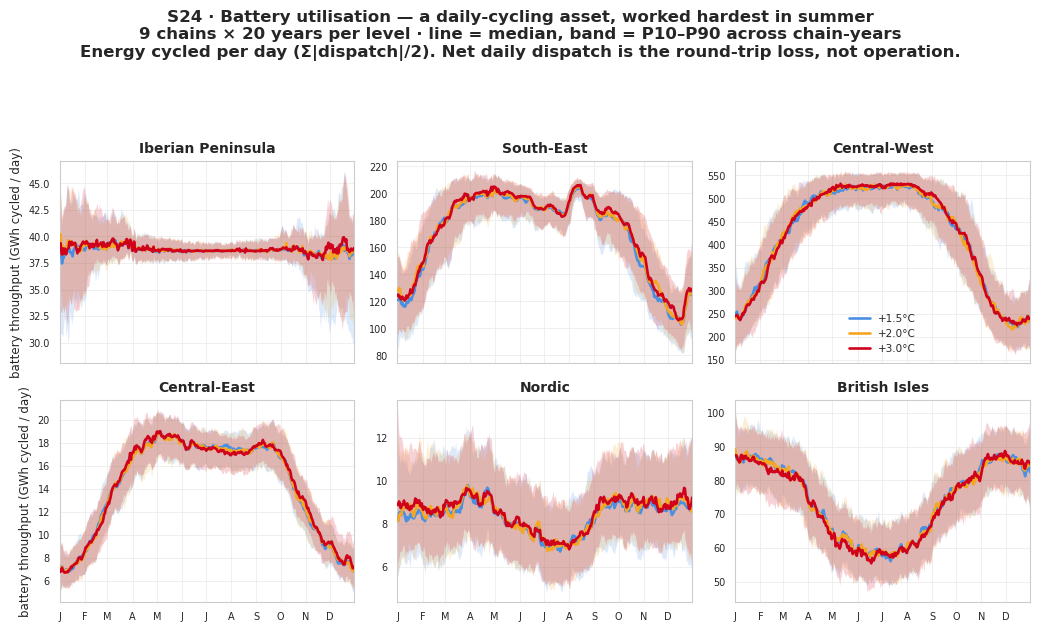

Battery throughput (GWh cycled/day, ensemble median):
  Iberian Peninsula  winter    38.8   summer    38.6   summer/winter  1.00x
  South-East         winter   129.2   summer   193.0   summer/winter  1.49x
  Central-West       winter   279.0   summer   521.5   summer/winter  1.87x
  Central-East       winter     8.2   summer    17.6   summer/winter  2.15x
  Nordic             winter     8.5   summer     7.3   summer/winter  0.86x
  British Isles      winter    85.6   summer    60.0   summer/winter  0.70x


In [26]:
# Zonal battery throughput. `main["components"]` is already the zonal components of the paper's run.
throughput = operation_curves(main["components"], "battery_dispatch_gwh", "zone", zones,
                              mode="throughput")
battery_panels = {ZONE_LABELS[z]: throughput[z] for z in zones}

fig = plot_seasonal_operation(
    battery_panels, STYLE, mode="band", ncols=3,
    ylabel="battery throughput (GWh cycled / day)",
    title="S24 · Battery utilisation — a daily-cycling asset, worked hardest in summer",
    caption="Energy cycled per day (Σ|dispatch|/2). Net daily dispatch is the round-trip loss, not operation.")
fig.savefig(FIGS / "S24_battery_throughput.png", dpi=200, bbox_inches="tight")
plt.show()

summer, winter = [6, 7, 8], [12, 1, 2]
print("Battery throughput (GWh cycled/day, ensemble median):")
for zone in zones:
    block = throughput[zone][REFERENCE]
    djf = np.median(block[:, [d for d in range(365) if (d < 59 or d >= 334)]])
    jja = np.median(block[:, 151:243])
    print(f"  {ZONE_LABELS[zone]:<18} winter {djf:7.1f}   summer {jja:7.1f}   summer/winter {jja/max(djf,1e-9):5.2f}x")

---

**Companion notebooks:** `paper_main_figures.ipynb` (Figs 1–4) and `paper_si_inputs.ipynb` (S1–S7).